## Driven Turbulence – Toy Hydrodynamics

### 0. Preamble

#### 0.1. Setup

This notebook couples a minimal solver for isothermal gas dynamics in two dimensions to a stochastic forcing field, to explore how different forcing methods act on a flow at matched Mach number or at matched energy injection rate. All quantities are measured in units of the box size $L$ and the sound speed $c_\symup{s}$ and the mean density $\rho_0$ which are set to one in the code.

In [1]:
%config InlineBackend.figure_formats = ["svg"]

import sys
import scipy as sc
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

print("python", sys.version.split()[0],
      "| numpy", np.__version__,
      "| scipy", sc.__version__,
      "| matplotlib", mpl.__version__)

cs, L, rho0 = 1.0, 1.0, 1.0
seed = 123

python 3.14.3 | numpy 2.3.5 | scipy 1.17.1 | matplotlib 3.10.8


### 1. Solver

#### 1.1. Equations

An isothermal gas has the pressure $p = c_\symup{s}^2\rho$ with a constant sound speed, so that the conservation of mass and momentum closes without an energy equation

$$\partial_t\rho + \nabla\cdot(\rho\,\mathbf{v}) = 0 \qquad \partial_t(\rho\,\mathbf{v}) + \nabla\cdot\left(\rho\,\mathbf{v}\mathbf{v}^\top + c_\symup{s}^2\rho\,\mathsf{I}\right) = \rho\,\mathbf{a}$$

where $\mathbf{a}$ is the external acceleration of the forcing. In two dimensions and with the conserved state $\mathbf{U} = (\rho, \rho v_x, \rho v_y)$ this is the system

$$\partial_t\mathbf{U} + \partial_x\mathbf{F} + \partial_y\mathbf{G} = \mathbf{S} \qquad \mathbf{F} = \begin{pmatrix}\rho v_x \\ \rho v_x^2 + c_\symup{s}^2\rho \\ \rho v_x v_y\end{pmatrix} \qquad \mathbf{G} = \begin{pmatrix}\rho v_y \\ \rho v_x v_y \\ \rho v_y^2 + c_\symup{s}^2\rho\end{pmatrix} \qquad \mathbf{S} = \begin{pmatrix}0 \\ \rho a_x \\ \rho a_y\end{pmatrix}$$

whose flux Jacobian along each axis has the eigenvalues $v - c_\symup{s}$ and $v$ and $v + c_\symup{s}$ with the velocity component $v$ along that axis, which are the speeds of the two sound waves and of the shear wave that carries the transverse velocity. Averaging over a square cell of side $\Delta x$ turns the divergence into a difference of fluxes through the faces

$$\frac{\symup{d}\mathbf{U}_{i,j}}{\symup{d}t} = -\frac{\mathbf{F}_{i+1/2,j} - \mathbf{F}_{i-1/2,j}}{\Delta x} - \frac{\mathbf{G}_{i,j+1/2} - \mathbf{G}_{i,j-1/2}}{\Delta x} + \mathbf{S}_{i,j}$$

which conserves mass and momentum to round off on a periodic grid for any choice of the face fluxes, since every flux enters two neighbouring cells with opposite signs.

#### 1.2. Reconstruction

The face fluxes need the state on both sides of every face. Taking the cell averages themselves gives a scheme of first order, and second order follows from a linear profile inside every cell with a slope $\boldsymbol{\sigma}_i$ per cell, written here along one axis for the primitive variables $\mathbf{W} = (\rho, v_x, v_y)$

$$\mathbf{W}^\symup{L}_{i+1/2} = \mathbf{W}_i + \frac{\boldsymbol{\sigma}_i}{2} \qquad \mathbf{W}^\symup{R}_{i+1/2} = \mathbf{W}_{i+1} - \frac{\boldsymbol{\sigma}_{i+1}}{2}$$

for the states left and right of the face. An unlimited slope overshoots at shocks and creates new extrema, so with the one sided differences $a = W_i - W_{i-1}$ and $b = W_{i+1} - W_i$ of every component we take their harmonic mean where they agree in sign and zero otherwise

$$\sigma_i = \frac{2ab}{a + b} \quad ab > 0 \qquad \sigma_i = 0 \quad ab \leq 0$$

which is the limiter of van Leer. In smooth regions it reduces to the central difference, since the harmonic and the arithmetic mean of nearly equal numbers agree to second order in their difference, and at extrema it flattens the profile, so that the face values stay between the neighbouring averages and the density stays positive at the faces.

#### 1.3. Riemann Solver

The two states at a face define a Riemann problem whose solution consists of waves leaving the face. Instead of resolving them, the solver of Harten, Lax and van Leer bounds the fan of waves by a slowest and a fastest signal speed

$$S_\symup{L} = \min(v_\symup{L}, v_\symup{R}) - c_\symup{s} \qquad S_\symup{R} = \max(v_\symup{L}, v_\symup{R}) + c_\symup{s}$$

and assumes a single constant state $\mathbf{U}^*$ in between. Integrating the conservation law over the region that the fan covers after a time $t$ from $S_\symup{L}t$ to $S_\symup{R}t$ gives

$$(S_\symup{R} - S_\symup{L})\,\mathbf{U}^* = S_\symup{R}\mathbf{U}_\symup{R} - S_\symup{L}\mathbf{U}_\symup{L} - (\mathbf{F}_\symup{R} - \mathbf{F}_\symup{L})$$

for the intermediate state, and the same balance over the part left of the face alone gives the flux through the face

$$\mathbf{F}^* = \mathbf{F}_\symup{L} + S_\symup{L}(\mathbf{U}^* - \mathbf{U}_\symup{L}) = \frac{S_\symup{R}\mathbf{F}_\symup{L} - S_\symup{L}\mathbf{F}_\symup{R} + S_\symup{L}S_\symup{R}(\mathbf{U}_\symup{R} - \mathbf{U}_\symup{L})}{S_\symup{R} - S_\symup{L}}$$

which holds when the face lies inside the fan with $S_\symup{L} < 0 < S_\symup{R}$ while a fan that moves entirely to one side leaves the upwind flux. Clipping the speeds to $S_\symup{L} \leq 0 \leq S_\symup{R}$ before inserting them covers all three cases with the same expression, since it then returns $\mathbf{F}_\symup{L}$ or $\mathbf{F}_\symup{R}$ exactly. The isothermal system has no contact wave in the density, so a fan of two waves only costs some sharpness of shear layers.

#### 1.4. Time Stepping

With the right side $\mathcal{L}(\mathbf{U})$ of the cell averaged system from reconstruction and face fluxes, the two stage scheme of Heun

$$\mathbf{U}^{(1)} = \mathbf{U}^n + \Delta t\,\mathcal{L}(\mathbf{U}^n) \qquad \mathbf{U}^{n+1} = \frac{1}{2}\left[\mathbf{U}^n + \mathbf{U}^{(1)} + \Delta t\,\mathcal{L}(\mathbf{U}^{(1)})\right]$$

is second order in time and a convex combination of forward Euler steps, so it inherits their stability. The step is limited by the fastest signal that crosses a cell

$$\Delta t = C\,\frac{\Delta x}{\max(|v_x|, |v_y|) + c_\symup{s}}$$

with a Courant number $C$ below one half, and under forcing also by the distance covered from rest with the largest acceleration

$$\Delta t \leq C\,\sqrt{\frac{\Delta x}{\max|\mathbf{a}|}}$$

so that a single kick cannot cross a cell either. A small density floor guards against negative densities in strong rarefactions.

In [2]:
def slopes(W, ax):
    """van leer limited differences along axis"""
    a, b = W - np.roll(W, 1, ax), np.roll(W, -1, ax) - W
    ab = a * b
    return np.where(ab > 0, 2 * ab / np.where(ab > 0, a + b, 1.0), 0.0)

def hll(W, ax):
    """flux through upper faces along axis from primitive variables"""
    s = 0.5 * slopes(W, ax)
    WL, WR = W + s, np.roll(W - s, -1, ax)
    vL, vR = WL[ax], WR[ax]
    SL = np.minimum(np.minimum(vL, vR) - cs, 0)                 # clipped speeds select upwind flux
    SR = np.maximum(np.maximum(vL, vR) + cs, 0)
    UL, UR = WL.copy(), WR.copy()
    UL[1:] *= WL[0]
    UR[1:] *= WR[0]
    FL, FR = UL * vL, UR * vR
    FL[ax] += cs**2 * WL[0]
    FR[ax] += cs**2 * WR[0]
    return (SR * FL - SL * FR + SL * SR * (UR - UL)) / (SR - SL)

def rhs(U, dx, a=None):
    """time derivative of conserved variables with optional acceleration"""
    W = U.copy()
    W[1:] /= U[0]
    fx, fy = hll(W, 1), hll(W, 2)
    dU = (np.roll(fx, 1, 1) - fx + np.roll(fy, 1, 2) - fy) / dx
    if a is not None:
        dU[1:] += U[0] * a
    return dU

def hydro_step(U, dt, dx, a=None, floor=1e-10):
    """two stage step, acceleration is passed through a function of the density"""
    U1 = U + dt * rhs(U, dx, None if a is None else a(U[0]))
    np.maximum(U1[0], floor, out=U1[0])
    U2 = 0.5 * (U + U1 + dt * rhs(U1, dx, None if a is None else a(U1[0])))
    np.maximum(U2[0], floor, out=U2[0])
    return U2

def evolve(U, t_end, C=0.4):
    """unforced evolution up to given time"""
    dx, t = L / U.shape[1], 0.0
    while t < t_end * (1 - 1e-12):
        dt = min(C * dx / (np.max(np.abs(U[1:] / U[0])) + cs), t_end - t)
        U = hydro_step(U, dt, dx)
        t += dt
    return U

#### 1.5. Tests

Three tests validate the solver without forcing. A sound wave of small amplitude $A$ that travels along the diagonal returns to its initial state after one period, and the error against the initial state approaches a decrease with the square of the cell size once the wave is well resolved, since the limiter clips the crests on coarse grids. A density jump at rest decays into a rarefaction and a shock, for which the Riemann problem has an exact solution. The density $\rho^*$ and the velocity $v^*$ between the two waves follow from the invariant $v + c_\symup{s}\ln\rho$ that is constant across the rarefaction moving into the dense side and from the jump conditions across the shock moving into the thin side

$$v^* = c_\symup{s}\ln\frac{\rho_\symup{L}}{\rho^*} \qquad v^* = c_\symup{s}\,\frac{\rho^* - \rho_\symup{R}}{\sqrt{\rho^*\rho_\symup{R}}}$$

whose common root is found numerically, and with it

$$S = c_\symup{s}\sqrt{\frac{\rho^*}{\rho_\symup{R}}} \qquad v = \frac{x}{t} + c_\symup{s} \qquad \rho = \rho_\symup{L}\,e^{-v/c_\symup{s}}$$

for the shock speed and for the self similar profile inside the rarefaction, which extends from its head at $x/t = -c_\symup{s}$ to its tail at $x/t = v^* - c_\symup{s}$ behind. The periodic box holds two mirrored jumps, so the numerical solution also has to stay mirror symmetric. Finally a rough random flow has to conserve the total mass and momentum to round off.

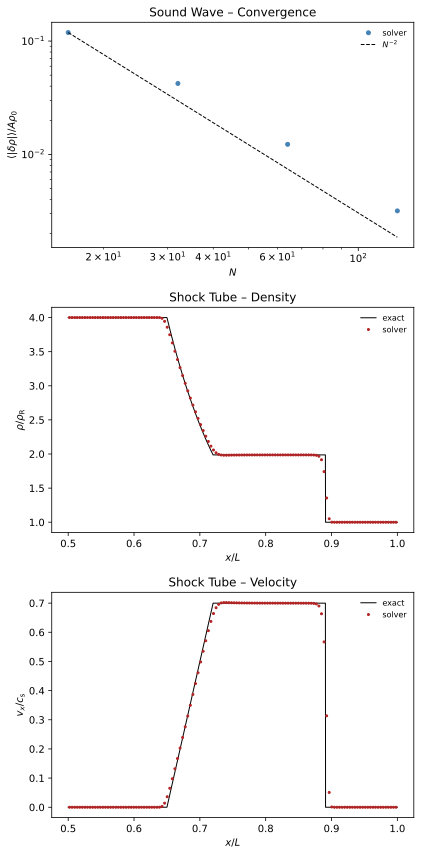

In [3]:
def sound_error(N, A=1e-4):
    """density error of a diagonal sound wave after one period, relative to its amplitude"""
    x = (np.arange(N) + 0.5) * L / N
    phi = 2 * np.pi * (x[:, None] + x[None, :]) / L
    U = np.empty((3, N, N))
    U[0] = rho0 * (1 + A * np.sin(phi))
    U[1] = U[2] = U[0] * A * cs * np.sin(phi) / np.sqrt(2)
    return np.mean(np.abs(evolve(U, L / (np.sqrt(2) * cs))[0] - U[0])) / (A * rho0)

def tube_exact(xi, rhoL, rhoR):
    """isothermal riemann solution for a density jump at rest against x/t"""
    root = lambda r: np.log(rhoL / r) - (r - rhoR) / np.sqrt(r * rhoR)
    rs = sc.optimize.brentq(root, rhoR, rhoL)
    vs, S = cs * np.log(rhoL / rs), cs * np.sqrt(rs / rhoR)
    v = np.where(xi < -cs, 0.0, np.where(xi < vs - cs, xi + cs, np.where(xi < S, vs, 0.0)))
    rho = np.where(xi < vs - cs, rhoL * np.exp(-v / cs), np.where(xi < S, rs, rhoR))
    return rho, v

Ns = np.array([16, 32, 64, 128])
err = np.array([sound_error(N) for N in Ns])
assert np.all(np.diff(err) < 0) and 1.8 < np.log2(err[-2] / err[-1]) < 2.2

N, t_end, rhoL, rhoR = 256, 0.1, 4.0, 1.0
x = (np.arange(N) + 0.5) * L / N
U = np.zeros((3, N, 4))
U[0] = np.where(np.abs(x - 0.5 * L) < 0.25 * L, rhoL, rhoR)[:, None]
U = evolve(U, t_end)
rho_n, v_n = U[0, :, 0], U[1, :, 0] / U[0, :, 0]
half = x > 0.5 * L
rho_e, v_e = tube_exact((x[half] - 0.75 * L) / t_end, rhoL, rhoR)
assert np.mean(np.abs(rho_n[half] - rho_e)) < 0.02 * rhoR and np.mean(np.abs(v_n[half] - v_e)) < 0.02 * cs
assert np.allclose(rho_n, rho_n[::-1], atol=1e-10) and np.allclose(v_n, -v_n[::-1], atol=1e-10)

rng = np.random.default_rng(seed)
U = np.empty((3, 64, 64))
U[0] = rho0 * (1 + 0.5 * rng.random((64, 64)))
U[1:] = U[0] * cs * rng.standard_normal((2, 64, 64))
total = np.sum(U, axis=(1, 2))
assert np.max(np.abs(np.sum(evolve(U, 0.2), axis=(1, 2)) - total)) < 1e-10 * total[0]

fig, ax = plt.subplots(3, 1, figsize=(6, 12))
ax[0].loglog(Ns, err, "o", color="steelblue", ms=4, label="solver")
ax[0].loglog(Ns, err[0] * (Ns / Ns[0])**-2.0, "--", color="k", lw=1, label="$N^{-2}$")
ax[0].set(xlabel="$N$", ylabel="$\\langle|\\delta\\rho|\\rangle / A\\rho_0$", title="Sound Wave – Convergence")
ax[0].legend(fontsize=8, edgecolor="none", handlelength=1.9)

xf = np.linspace(0.5 * L, L, 2000)
rho_f, v_f = tube_exact((xf - 0.75 * L) / t_end, rhoL, rhoR)
for k, (num, exact, lab) in enumerate([(rho_n, rho_f, "$\\rho/\\rho_\\mathrm{R}$"), (v_n, v_f, "$v_x/c_\\mathrm{s}$")]):
    ax[k + 1].plot(xf / L, exact, "-", color="k", lw=1, label="exact")
    ax[k + 1].plot(x[half] / L, num[half], "o", color="firebrick", ms=2, label="solver")
    ax[k + 1].set(xlabel="$x/L$", ylabel=lab, title="Shock Tube – " + ["Density", "Velocity"][k])
    ax[k + 1].legend(fontsize=8, edgecolor="none", handlelength=1.9)

fig.tight_layout()
plt.show()

### 2. Forcing

#### 2.1. Field

The forcing follows the convention of [Schmidt 2006] and [Federrath 2010] and is a Gaussian random field built from few Fourier modes in a shell around the driving wavenumber $k_\symup{d} = 2\pi/\ell_\symup{d}$ of the driving scale $\ell_\symup{d}$ with a parabolic profile $w(k)$ that vanishes at the edges of the shell

$$\mathbf{a}(\mathbf{x},t) = 2 a_0\,\symup{Re}\sum_{\mathbf{k}\in\mathcal{H}} \mathsf{P}_\zeta\,\hat{\mathbf{g}}_\mathbf{k}(t)\,e^{i\mathbf{k}\cdot\mathbf{x}} \qquad \mathsf{P}_\zeta = \zeta\,\mathsf{P}^\perp + (1-\zeta)\,\mathsf{P}^\parallel$$

where the sum runs over the half space $\mathcal{H}$ of wavevectors whose first nonzero component is positive, and where the projectors across and along the wavevector mix solenoidal and compressive driving through the weight $\zeta$ that runs from purely compressive at $\zeta = 0$ over the natural mixture at $\zeta = 1/2$ to purely solenoidal at $\zeta = 1$ on the other end. Every component of the complex amplitudes $\hat{\mathbf{g}}_\mathbf{k}$ is an independent Ornstein-Uhlenbeck process with the correlation time $T$ that advances with its exact update

$$\hat{\mathbf{g}}_\mathbf{k}^{n+1} = A\,\hat{\mathbf{g}}_\mathbf{k}^n + s_k\sqrt{1 - A^2}\,(\boldsymbol{\xi} + i\,\boldsymbol{\xi}^\prime) \qquad A = e^{-\Delta t/T} \qquad s_k = \frac{w(k)}{2\sqrt{\left[\zeta^2 + (1-\zeta)^2\right]\sum w^2}}$$

with independent standard normal vectors $\boldsymbol{\xi}$ and $\boldsymbol{\xi}^\prime$ for every mode and step, so that the statistics do not depend on the sequence of step sizes. The normalization $s_k$ makes the root mean square acceleration equal to the amplitude $a_0$ for every mixture, and in two dimensions the fraction of the forcing power in compressive modes is

$$\chi = \frac{(1-\zeta)^2}{\zeta^2 + (1-\zeta)^2}$$

since one direction lies along and one across every wavevector.

#### 2.2. Coupling

The forcing enters the momentum equation as the source $\rho\,\mathbf{a}$ and is held fixed during a step, after which the amplitudes advance by the same step. Three ways of coupling the source to the solver are implemented, where $\mathcal{K}_h$ denotes a kick that adds $h\,\rho\,\mathbf{a}$ to the momentum at fixed density and $\mathcal{H}_{\Delta t}$ a step of the unforced solver:

* **Kick:** the composition $\mathcal{K}_{\Delta t}\mathcal{H}_{\Delta t}$ of a full step and a full kick is first order in time
* **Strang:** the symmetric composition $\mathcal{K}_{\Delta t/2}\mathcal{H}_{\Delta t}\mathcal{K}_{\Delta t/2}$ with two half kicks is second order
* **Stage:** the source is added to the right side in both stages of the time integrator, which is second order without any splitting

A kick changes the kinetic energy $E = \langle\rho\,\mathbf{v}^2\rangle/2$ per volume by exactly

$$\Delta E = h\,\langle\rho\,\mathbf{v}\cdot\mathbf{a}\rangle + \frac{h^2}{2}\,\langle\rho\,\mathbf{a}^2\rangle$$

where the angle brackets denote the average over the box, which follows from expanding the square of the kicked velocity. The first term is the work of the force on the flow before the kick and the second term is the energy of the kick itself, which is positive for any force and is the only contribution that survives when the force is white in time. Summing this expression over all kicks gives the injected energy without discretization error, and the run records it per step as the injection rate $\varepsilon$ of the flow.

#### 2.3. Momentum

The modes exclude the wavevector zero, so the acceleration has no mean, but the force density $\rho\,\mathbf{a}$ does once the density is not uniform, and the box starts to drift. Subtracting the mass weighted mean

$$\mathbf{a}^\prime = \mathbf{a} - \frac{\langle\rho\,\mathbf{a}\rangle}{\langle\rho\rangle}$$

with the current density before every kick and in every stage removes the net force exactly, so the total momentum stays at round off.

#### 2.4. Energy

Without an energy equation the work of compression is not stored as heat, yet smooth isothermal flow still conserves an energy. The time derivatives of the kinetic energy and of the functional $H = c_\symup{s}^2\langle\rho\ln(\rho/\rho_0)\rangle$ follow from the equations of motion after integration by parts on the periodic box

$$\frac{\symup{d}E}{\symup{d}t} = c_\symup{s}^2\langle\rho\,\nabla\cdot\mathbf{v}\rangle + \langle\rho\,\mathbf{v}\cdot\mathbf{a}\rangle \qquad \frac{\symup{d}H}{\symup{d}t} = c_\symup{s}^2\left\langle\left[\ln\frac{\rho}{\rho_0} + 1\right]\partial_t\rho\right\rangle = -c_\symup{s}^2\langle\rho\,\nabla\cdot\mathbf{v}\rangle$$

so the pressure work cancels in the sum and $E + H$ changes only through the forcing, while $H$ is never negative by the convexity of $\rho\ln\rho$ and measures the energy stored in compression. Shocks are not smooth and dissipate, so the balance of a driven box reads

$$\frac{\symup{d}}{\symup{d}t}(E + H) = \varepsilon - \varepsilon_\symup{diss}$$

with a dissipation rate $\varepsilon_\symup{diss}$ that the scheme supplies through its numerical viscosity and that follows from the recorded quantities as a residual. In a statistically stationary state injection and dissipation balance on average.

#### 2.5. Interface

Every step records the time and the step size, the volume weighted Mach number $\mathcal{M}$ as the root mean square velocity over the sound speed, both energies, the injection rate, the mean momentum, the width of the logarithmic density and the correlation coefficient between force and velocity

$$r = \frac{\langle\rho\,\mathbf{v}\cdot\mathbf{a}\rangle}{\sqrt{\langle\rho\,\mathbf{v}^2\rangle\langle\rho\,\mathbf{a}^2\rangle}}$$

which measures how efficiently a given force does work on a given flow. Any other forcing method couples to the solver through the same two methods as the class below, where `step` advances the forcing in time and `accel` returns the acceleration at the cell centres, for which it receives the current state and the size of the coming step, so that alternative methods can be compared without touching the solver.

[Schmidt 2006]: https://arxiv.org/abs/astro-ph/0407616
[Federrath 2010]: https://doi.org/10.1051/0004-6361/200912437

In [4]:
def momentum_free(a, rho):
    """acceleration minus its mass weighted mean"""
    return a - np.mean(rho * a, axis=(1, 2), keepdims=True) / np.mean(rho)

def kick(U, a, h, subtract=True):
    """momentum kick in place, returns kinetic energy gained"""
    if subtract:
        a = momentum_free(a, U[0])
    work = h * np.mean(np.sum(U[1:] * a, axis=0)) + 0.5 * h**2 * np.mean(U[0] * np.sum(a**2, axis=0))
    U[1:] += h * U[0] * a
    return work

def forcing_modes(nd=2.0, dn=1.0):
    """half space wavevectors of driving shell with parabolic profile"""
    m = int(np.ceil(nd + dn))
    n = np.indices((2 * m + 1,) * 2).reshape(2, -1).T - m
    first = n[np.arange(len(n)), np.argmax(n != 0, axis=1)]     # first nonzero component
    r = np.linalg.norm(n, axis=1)
    keep = (first > 0) & (np.abs(r - nd) < dn)
    return 2 * np.pi * n[keep] / L, 1 - ((r[keep] - nd) / dn)**2

class ForcingField:
    """stochastic forcing at cell centres with exact mode update"""

    def __init__(self, N, T, zeta, amp, seed, nd=2.0, dn=1.0):
        self.k, w = forcing_modes(nd, dn)
        u = self.k / np.linalg.norm(self.k, axis=1, keepdims=True)
        par = u[:, :, None] * u[:, None, :]
        self.P = zeta * (np.eye(2) - par) + (1 - zeta) * par
        self.s = w / np.sqrt(4 * (zeta**2 + (1 - zeta)**2) * np.sum(w**2))
        x = (np.arange(N) + 0.5) * L / N
        self.phase = np.exp(1j * (self.k[:, 0, None, None] * x[:, None] + self.k[:, 1, None, None] * x[None, :]))
        self.T, self.amp, self.seed, self.count = T, amp, seed, 0
        self.g = self.s[:, None] * self._draw(0)                # stationary start

    def _draw(self, key):
        """complex standard normals for all modes from seed and key alone"""
        rng = np.random.default_rng([self.seed, key])
        return rng.standard_normal(self.k.shape) + 1j * rng.standard_normal(self.k.shape)

    def step(self, dt):
        """exact update of all amplitudes over one step"""
        A = np.exp(-dt / self.T)
        self.count += 1
        self.g = A * self.g + self.s[:, None] * np.sqrt(1 - A**2) * self._draw(self.count)

    def accel(self, U=None, dt=None):
        """acceleration at cell centres, state and step size are not needed here"""
        Fh = np.einsum("kij,kj->ki", self.P, self.g)
        return 2 * self.amp * np.real(np.einsum("ki,kxy->ixy", Fh, self.phase))

def helmholtz(v):
    """compressive part of a periodic vector field"""
    n = np.fft.fftfreq(v.shape[1], 1 / v.shape[1])
    kx, ky = np.meshgrid(n, n, indexing="ij")
    vh = np.fft.fft2(v)
    dh = (kx * vh[0] + ky * vh[1]) / np.maximum(kx**2 + ky**2, 1)
    return np.real(np.fft.ifft2(np.stack([kx * dh, ky * dh])))

def run(N, forcing, t_end, coupling="strang", subtract=True, C=0.4, snap_dt=None):
    """driven run from rest, returns final state, log of diagnostics and snapshots at fixed intervals"""
    dx = L / N
    U = np.zeros((3, N, N))
    U[0] = rho0
    t, log, snaps, cuts = 0.0, [], [], []
    while t < t_end * (1 - 1e-12):
        dt = C * dx / (np.max(np.abs(U[1:] / U[0])) + cs)
        a = forcing.accel(U, dt)
        dt = min(dt, C * np.sqrt(dx / (np.max(np.abs(a)) + 1e-300)), t_end - t)
        if coupling == "strang":
            work = kick(U, a, 0.5 * dt, subtract)
            U = hydro_step(U, dt, dx)
            work += kick(U, a, 0.5 * dt, subtract)
        elif coupling == "kick":
            U = hydro_step(U, dt, dx)
            work = kick(U, a, dt, subtract)
        else:
            af = (lambda rho: momentum_free(a, rho)) if subtract else (lambda rho: a)
            work = 0.5 * dt * np.mean(np.sum(U[1:] * af(U[0]), axis=0))
            U = hydro_step(U, dt, dx, af)
            work += 0.5 * dt * np.mean(np.sum(U[1:] * af(U[0]), axis=0))    # trapezoidal estimate
        forcing.step(dt)
        t += dt
        s = np.log(U[0] / rho0)
        rv2, ra2 = np.mean(np.sum(U[1:]**2, axis=0) / U[0]), np.mean(U[0] * np.sum(a**2, axis=0))
        log.append((t, dt, np.sqrt(np.mean(np.sum(U[1:]**2, axis=0) / U[0]**2)) / cs, 0.5 * rv2,
                    cs**2 * np.mean(U[0] * s), work / dt, np.mean(U[1]), np.mean(U[2]),
                    np.mean(np.sum(U[1:] * a, axis=0)) / np.sqrt(rv2 * ra2 + 1e-300), np.std(s)))
        if snap_dt is not None:
            cuts.append((s[:, N // 2], a[0][:, N // 2]))        # cut through the middle of the box
            if t >= (len(snaps) + 1) * snap_dt * (1 - 1e-12):
                snaps.append(U.copy())
    keys = ("t", "dt", "mach", "E", "H", "eps", "px", "py", "r", "sigma")
    log = dict(zip(keys, np.array(log).T))
    log["cuts"] = np.array(cuts)
    return U, log, snaps

def average(log, key, t_min):
    """time average of a recorded quantity after t_min"""
    late = log["t"] > t_min
    return np.sum(log[key][late] * log["dt"][late]) / np.sum(log["dt"][late])

#### 2.6. Tests

The tests check the root mean square of the acceleration and its compressive fraction over many independent seeds, the kick energy against a direct evaluation, the conservation of momentum for all three couplings with the subtraction switched on, and that two runs with the same seed agree bit by bit. With a frozen pattern the solution does not depend on the random draws, so the convergence of the three couplings with the step size can be measured against a reference run with a much smaller step, where the kick coupling has to converge at first order and the other two at second order. The second panel shows the drift of the box with and without the subtraction of the mean force.

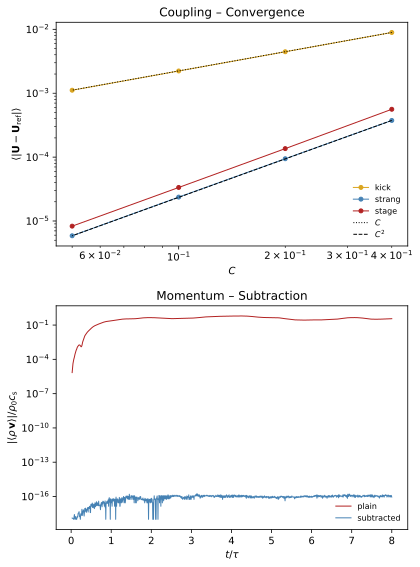

In [5]:
N = 32
for zeta in (0.0, 0.5, 1.0):
    a = np.array([ForcingField(N, 1.0, zeta, 1.0, s).accel() for s in range(400)])
    ac = np.array([helmholtz(ai) for ai in a])
    chi = (1 - zeta)**2 / (zeta**2 + (1 - zeta)**2)
    assert abs(np.mean(np.sum(a**2, axis=1)) - 1) < 0.1 and abs(np.mean(ac**2) / np.mean(a**2) - chi) < 0.05

rng = np.random.default_rng(seed)
U = np.empty((3, N, N))
U[0] = rho0 * (1 + rng.random((N, N)))
U[1:] = U[0] * cs * rng.standard_normal((2, N, N))
E0 = 0.5 * np.mean(np.sum(U[1:]**2, axis=0) / U[0])
work = kick(U, ForcingField(N, 1.0, 0.5, 3.0, seed).accel(), 0.1)
assert np.isclose(0.5 * np.mean(np.sum(U[1:]**2, axis=0) / U[0]) - E0, work, rtol=1e-12)

finals = {}
for coupling in ("kick", "strang", "stage"):
    Uc, log, _ = run(N, ForcingField(N, 0.25, 0.5, 10.0, seed), 0.5, coupling)
    assert np.max(np.abs(log["px"])) < 1e-12 and np.max(np.abs(log["py"])) < 1e-12
    finals[coupling] = Uc
assert np.array_equal(finals["strang"], run(N, ForcingField(N, 0.25, 0.5, 10.0, seed), 0.5)[0])

frozen = lambda: ForcingField(N, np.inf, 0.5, 5.0, seed)
Cs = np.array([0.4, 0.2, 0.1, 0.05])
ref = run(N, frozen(), 0.1, "strang", C=0.005)[0]
conv = {c: np.array([np.mean(np.abs(run(N, frozen(), 0.1, c, C=Ci)[0] - ref)) for Ci in Cs]) for c in finals}
orders = {c: np.polyfit(np.log(Cs), np.log(conv[c]), 1)[0] for c in finals}
assert 0.8 < orders["kick"] < 1.3 and orders["strang"] > 1.7 and orders["stage"] > 1.7

tau_t = 0.25
drift = {s: run(64, ForcingField(64, tau_t, 0.5, 12.0, seed), 8 * tau_t, subtract=s)[1] for s in (False, True)}

fig, ax = plt.subplots(2, 1, figsize=(6, 8))
for c, col in [("kick", "goldenrod"), ("strang", "steelblue"), ("stage", "firebrick")]:
    ax[0].loglog(Cs, conv[c], "o-", color=col, lw=1, ms=4, label=c)
ax[0].loglog(Cs, conv["kick"][0] * Cs / Cs[0], ":", color="k", lw=1, label="$C$")
ax[0].loglog(Cs, conv["strang"][0] * (Cs / Cs[0])**2, "--", color="k", lw=1, label="$C^2$")
ax[0].set(xlabel="$C$", ylabel="$\\langle|\\mathbf{U} - \\mathbf{U}_\\mathrm{ref}|\\rangle$", title="Coupling – Convergence")
ax[0].legend(fontsize=8, edgecolor="none", handlelength=1.9)

for s, col, lab in [(False, "firebrick", "plain"), (True, "steelblue", "subtracted")]:
    p = np.hypot(drift[s]["px"], drift[s]["py"]) / (rho0 * cs)
    ax[1].semilogy(drift[s]["t"] / tau_t, np.maximum(p, 1e-18), "-", color=col, lw=1, label=lab)
ax[1].set(xlabel="$t/\\tau$", ylabel="$|\\langle\\rho\\,\\mathbf{v}\\rangle| / \\rho_0 c_\\mathrm{s}$", title="Momentum – Subtraction")
ax[1].legend(fontsize=8, edgecolor="none", handlelength=1.9)

fig.tight_layout()
plt.show()

### 3. Calibration

#### 3.1. Scaling

Different forcing methods are only comparable at the same strength of the turbulence, and the amplitude that produces a given Mach number depends on the mixture, on the correlation time and on the method itself. In a stationary state the injection balances the dissipation, and for a velocity $v$ at the driving scale both can be estimated

$$\varepsilon \sim r\,\rho_0\,a_0\,v \qquad \varepsilon_\symup{diss} \sim \frac{\rho_0\,v^3}{\ell_\symup{d}}$$

from the work of the force with the correlation coefficient from above and from the energy of the driving scale that is dissipated within one turnover, so that equating both gives

$$v^2 \sim r\,a_0\,\ell_\symup{d}$$

and the Mach number grows roughly with the square root of the amplitude and the injection rate with its power of three halves, as long as the correlation coefficient does not change much. All times below are measured in units of the turnover time at the driving scale for the target Mach number

$$\tau = \frac{\ell_\symup{d}}{\mathcal{M}\,c_\symup{s}}$$

which is also the default correlation time of the forcing as in [Federrath 2010] and the unit for the duration of all runs.

#### 3.2. Iteration

The function below finds the amplitude by repeating a cheap run at low resolution. With the logarithm $x$ of the amplitude and the logarithm $y$ of the time average of the target quantity after the spin up, every run gives one point, and the next amplitude follows from the secant through the last two points

$$x_{i+1} = x_i + \frac{y_\symup{target} - y_i}{m_i} \qquad m_i = \frac{y_i - y_{i-1}}{x_i - x_{i-1}}$$

where the first step takes its slope from the scaling above and where the slope is clipped to a plausible range, since averages over a finite time are noisy. The forcing is rebuilt with the same seed for every run, so the random numbers stay the same and only the amplitude changes. The target is either the Mach number or the injection rate, selected through the name of the recorded quantity, and the forcing enters only through a function that builds it for a given resolution and amplitude, so any method with the interface of the previous section can be matched in the same way.

[Federrath 2010]: https://doi.org/10.1051/0004-6361/200912437

In [6]:
def calibrate(make, target, tau, key="mach", N=64, amp=10.0, iters=3, turns=8, skip=3):
    """amplitude that reaches target mach number or injection rate by secant steps in log space"""
    x, y = [], []
    for i in range(iters):
        log = run(N, make(N, amp), turns * tau)[1]
        x.append(np.log(amp))
        y.append(np.log(average(log, key, skip * tau)))
        slope = (y[-1] - y[-2]) / (x[-1] - x[-2]) if i > 0 else (0.5 if key == "mach" else 1.5)
        amp *= np.exp((np.log(target) - y[-1]) / np.clip(slope, 0.25, 2.0))
    return amp

#### 3.3. Tests

The purely solenoidal, the natural and the purely compressive mixture are calibrated to the same Mach number at low resolution and then run at the production resolution, where the average Mach number after the spin up has to land near the target. As a second check the compressive forcing is calibrated to the injection rate of the solenoidal run instead, which then leaves it at a lower Mach number. The first panel shows the Mach number of the three matched runs against time, and the second panel shows the energy budget of the compressive run with the injected energy, the stored energy $E + H$ and the dissipated energy as their difference.

mach [1.89 2.05 2.18] | at matched injection 1.64


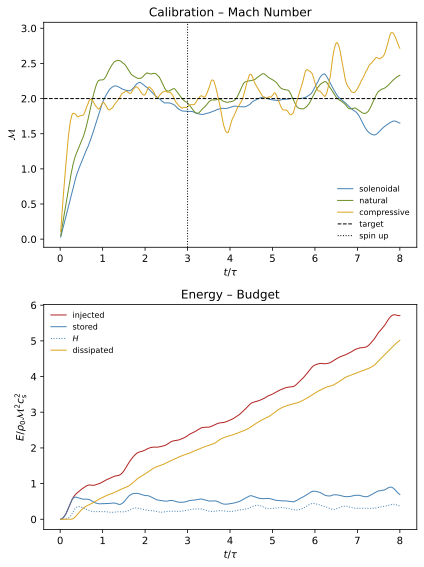

In [7]:
mach, ld, Np = 2.0, 0.5 * L, 128
tau = ld / (mach * cs)
turns, skip, per = 8, 3, 4                                      # duration, spin up, snapshots per turnover
mixes = [(1.0, "steelblue", "solenoidal"), (0.5, "olivedrab", "natural"), (0.0, "goldenrod", "compressive")]

runs = {}
for zeta, _, _ in mixes:
    make = lambda N, amp: ForcingField(N, tau, zeta, amp, seed)
    amp = calibrate(make, mach, tau)
    field = make(Np, amp)
    _, log, snaps = run(Np, field, turns * tau, snap_dt=tau / per)
    runs[zeta] = {"amp": amp, "log": log, "series": snaps, "snaps": snaps[skip * per:], "accel": field.accel(),
                  "mach": average(log, "mach", skip * tau)}
    assert abs(runs[zeta]["mach"] / mach - 1) < 0.25

make = lambda N, amp: ForcingField(N, tau, 0.0, amp, seed)
eps_target = average(run(64, ForcingField(64, tau, 1.0, runs[1.0]["amp"], seed), turns * tau)[1], "eps", skip * tau)
log_eps = run(64, make(64, calibrate(make, eps_target, tau, key="eps")), turns * tau)[1]
assert abs(average(log_eps, "eps", skip * tau) / eps_target - 1) < 0.25
print("mach", np.round([runs[z]["mach"] for z, _, _ in mixes], 2), "| at matched injection", np.round(average(log_eps, "mach", skip * tau), 2))

fig, ax = plt.subplots(2, 1, figsize=(6, 8))
for zeta, col, lab in mixes:
    ax[0].plot(runs[zeta]["log"]["t"] / tau, runs[zeta]["log"]["mach"], "-", color=col, lw=1, label=lab)
ax[0].axhline(mach, color="k", ls="--", lw=1, label="target")
ax[0].axvline(skip, color="k", ls=":", lw=1, label="spin up")
ax[0].set(xlabel="$t/\\tau$", ylabel="$\\mathcal{M}$", title="Calibration – Mach Number")
ax[0].legend(fontsize=8, edgecolor="none", handlelength=1.9)

log = runs[0.0]["log"]
unit = rho0 * (mach * cs)**2
injected = np.cumsum(log["eps"] * log["dt"])
ax[1].plot(log["t"] / tau, injected / unit, "-", color="firebrick", lw=1, label="injected")
ax[1].plot(log["t"] / tau, (log["E"] + log["H"]) / unit, "-", color="steelblue", lw=1, label="stored")
ax[1].plot(log["t"] / tau, log["H"] / unit, ":", color="steelblue", lw=1, label="$H$")
ax[1].plot(log["t"] / tau, (injected - log["E"] - log["H"]) / unit, "-", color="goldenrod", lw=1, label="dissipated")
ax[1].set(xlabel="$t/\\tau$", ylabel="$E/\\rho_0\\mathcal{M}^2c_\\mathrm{s}^2$", title="Energy – Budget")
ax[1].legend(fontsize=8, edgecolor="none", handlelength=1.9)

fig.tight_layout()
plt.show()

### 4. Experiments

#### 4.1. Maps

The rows of the figure show the three matched runs at the end of the simulation. The first column shows the logarithmic density $s = \ln(\rho/\rho_0)$ of the gas itself, which in a two dimensional flow is neither a slice nor a projection, with arrows for the acceleration of the forcing at that time on a coarse regular grid. The second and the third column show the divergence and the vorticity of the velocity

$$\nabla\cdot\mathbf{v} = \partial_x v_x + \partial_y v_y \qquad \omega = \partial_x v_y - \partial_y v_x$$

in units of the inverse turnover time, where a strongly negative divergence marks shocks and the vorticity marks shear layers and eddies. Every structure is a line in two dimensions, since nothing can break up a shock front along the missing direction, which together with the few large driving modes explains the sheet like appearance.

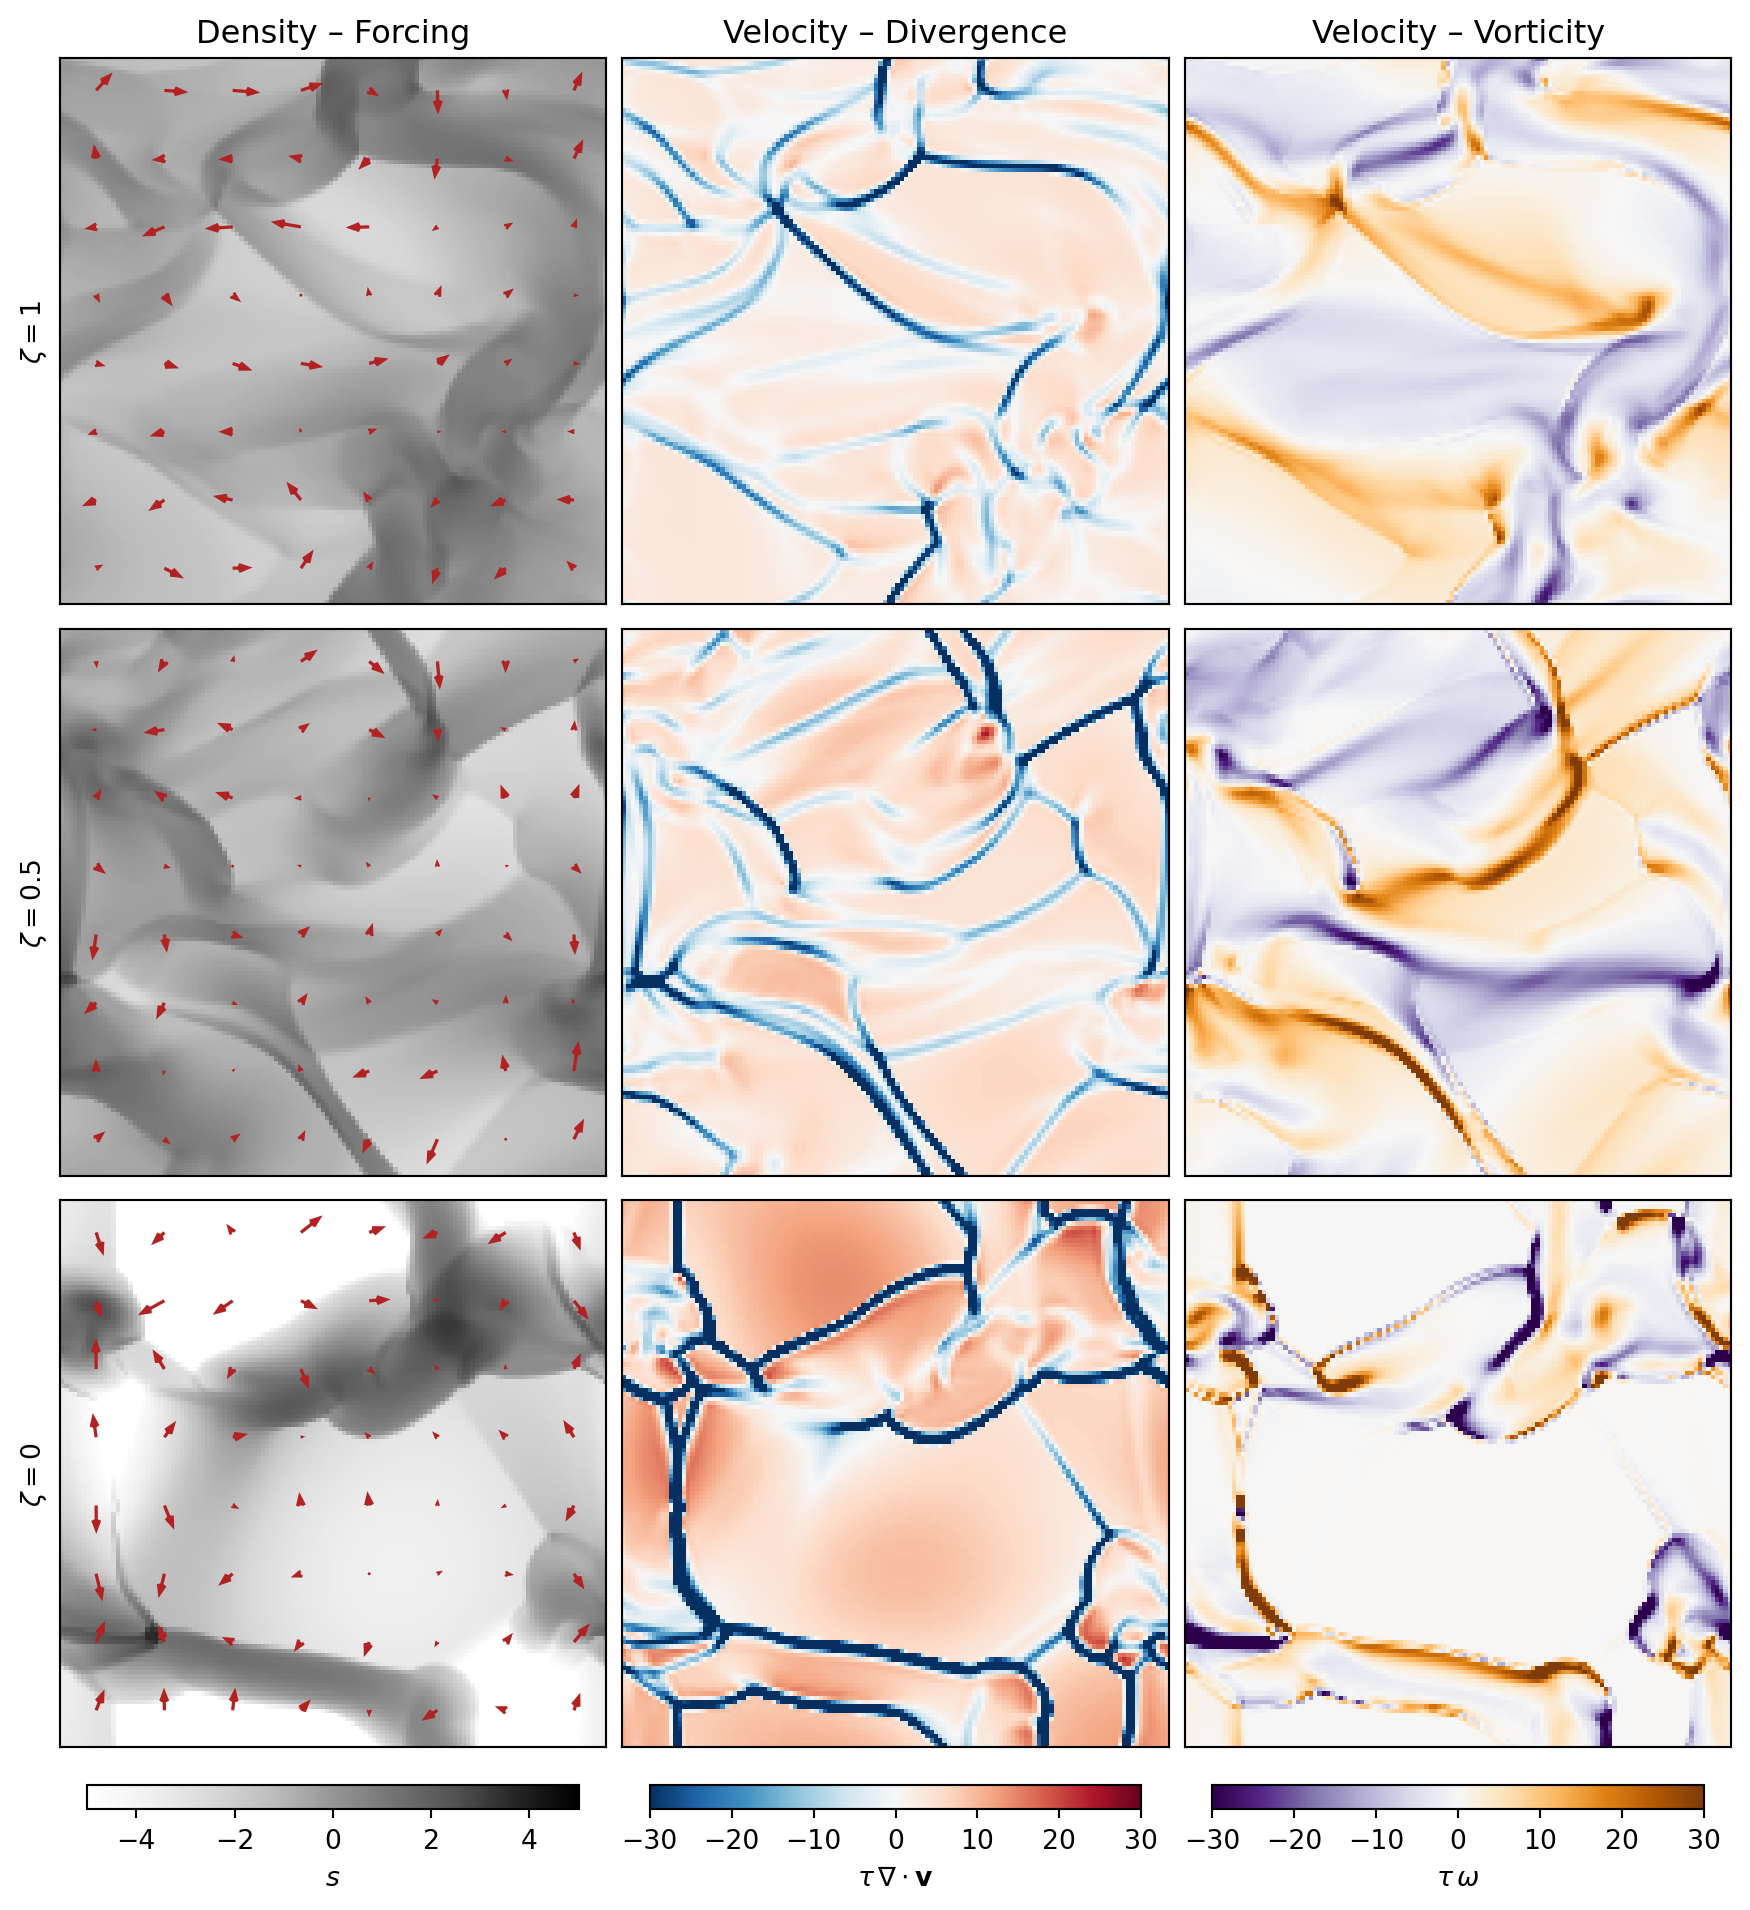

In [8]:
def derivatives(U):
    """divergence and vorticity of the velocity from central differences"""
    v, h = U[1:] / U[0], 2 * L / U.shape[1]
    d = lambda q, ax: (np.roll(q, -1, ax) - np.roll(q, 1, ax)) / h
    return d(v[0], 0) + d(v[1], 1), d(v[1], 0) - d(v[0], 1)

every = Np // 8                                                 # arrows on a coarse regular grid
pick = np.arange(every // 2, Np, every)
xa = (pick + 0.5) * L / Np

fig, ax = plt.subplots(3, 3, figsize=(9, 9.8), dpi=96, layout="constrained")
for k, (zeta, _, lab) in enumerate(mixes):
    U = runs[zeta]["snaps"][-1]
    div, rot = derivatives(U)
    a = runs[zeta]["accel"][:, pick][:, :, pick]
    im0 = ax[k, 0].imshow(np.log(U[0] / rho0).T, origin="lower", extent=(0, 1, 0, 1), cmap="Greys", vmin=-5, vmax=5)
    ax[k, 0].quiver(*np.meshgrid(xa, xa, indexing="ij"), a[0], a[1], color="firebrick", width=0.006, headwidth=3, headlength=4,
                    angles="xy", scale_units="xy", scale=np.max(np.hypot(a[0], a[1])) / (0.45 * every / Np))
    im1 = ax[k, 1].imshow(div.T * tau, origin="lower", extent=(0, 1, 0, 1), cmap="RdBu_r", vmin=-30, vmax=30)
    im2 = ax[k, 2].imshow(rot.T * tau, origin="lower", extent=(0, 1, 0, 1), cmap="PuOr_r", vmin=-30, vmax=30)
    ax[k, 0].set_ylabel(f"$\\zeta = {zeta:g}$")
for a_ in ax.ravel():
    a_.set(xticks=[], yticks=[])
for k, (im, lab) in enumerate([(im0, "$s$"), (im1, "$\\tau\\,\\nabla\\cdot\\mathbf{v}$"), (im2, "$\\tau\\,\\omega$")]):
    ax[0, k].set_title(["Density – Forcing", "Velocity – Divergence", "Velocity – Vorticity"][k])
    fig.colorbar(im, ax=ax[:, k], orientation="horizontal", shrink=0.9, pad=0.02, label=lab)

%config InlineBackend.figure_formats = ["retina"]   # images embedded in svg do not display on github
plt.show()
%config InlineBackend.figure_formats = ["svg"]

#### 4.2. Density

Compressive driving produces much stronger density contrasts than solenoidal driving at the same Mach number, as [Federrath 2008] showed. The distribution of the logarithmic density is close to a normal distribution whose width grows with the Mach number

$$\sigma_s^2 = \ln\left(1 + b^2\mathcal{M}^2\right) \qquad \tilde{b} = \frac{1}{D} + \frac{D-1}{D}\,\chi^3$$

with a parameter $b$ that depends on the driving, for which [Federrath 2010] gives the fit on the right with the dimension $D$ and the compressive fraction $\chi$ of the forcing. The distributions are weighted by volume and accumulated over all snapshots after the spin up, and the normal distributions with the predicted width for the measured Mach number have the mean $-\sigma_s^2/2$ that keeps the mean density fixed. The second panel compares the measured widths with the prediction across mixtures, with the scatter between snapshots as error bars. In the runs shown here the solenoidal and the natural mixture land near the fit, while the compressive run is much wider and has a long tail of evacuated regions, so the fit should not be trusted for compressive driving in this toy model.

[Federrath 2008]: https://doi.org/10.1086/595280
[Federrath 2010]: https://doi.org/10.1051/0004-6361/200912437

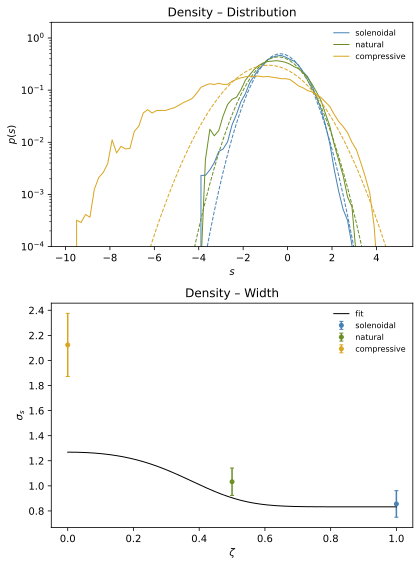

In [9]:
b_fit = lambda zeta, D=2: 1 / D + (D - 1) / D * ((1 - zeta)**2 / (1 - 2 * zeta + D * zeta**2))**3
width = lambda zeta, M: np.sqrt(np.log(1 + b_fit(zeta)**2 * M**2))

edges = np.linspace(-10, 5, 76)
mid = 0.5 * (edges[1:] + edges[:-1])
zg = np.linspace(0, 1, 200)

fig, ax = plt.subplots(2, 1, figsize=(6, 8))
for zeta, col, lab in mixes:
    s = np.log(np.array([U[0] for U in runs[zeta]["snaps"]]) / rho0)
    sig = np.std(s, axis=(1, 2))
    runs[zeta]["sigma"] = (np.mean(sig), np.std(sig))
    w = width(zeta, runs[zeta]["mach"])
    ax[0].semilogy(mid, np.histogram(s, edges, density=True)[0], "-", color=col, lw=1, label=lab)
    ax[0].semilogy(mid, np.exp(-0.5 * ((mid + 0.5 * w**2) / w)**2) / (w * np.sqrt(2 * np.pi)), "--", color=col, lw=1)
    ax[1].errorbar(zeta, *runs[zeta]["sigma"], fmt="o", color=col, ms=4, capsize=2, label=lab)
assert runs[0.0]["sigma"][0] > max(runs[0.5]["sigma"][0], runs[1.0]["sigma"][0])
ax[0].set(ylim=(1e-4, 2), xlabel="$s$", ylabel="$p(s)$", title="Density – Distribution")
ax[0].legend(fontsize=8, edgecolor="none", handlelength=1.9)

ax[1].plot(zg, width(zg, mach), "-", color="k", lw=1, label="fit")
ax[1].set(xlabel="$\\zeta$", ylabel="$\\sigma_s$", title="Density – Width")
ax[1].legend(fontsize=8, edgecolor="none", handlelength=1.9)

fig.tight_layout()
plt.show()

#### 4.3. Spectra

The velocity field splits into a compressive and a solenoidal part in Fourier space with the same projectors as the forcing, and the power summed over shells of integer wavenumber $n = kL/2\pi$ gives the spectrum $P(n)$ of the full field and $P_\parallel(n)$ of its compressive part. A flow that is dominated by shocks has a spectrum that falls with the square of the wavenumber, which is shown as a guide next to the shaded driving shell. The second panel shows the compressive fraction of the velocity power at every wavenumber, with the compressive fraction of the forcing as dotted lines, which shows how much of the mixture the flow remembers below the driving scale. In the runs shown here the mixtures stay distinct near the driving scale and converge towards mostly compressive motions at small scales, where shocks and the numerical dissipation dominate.

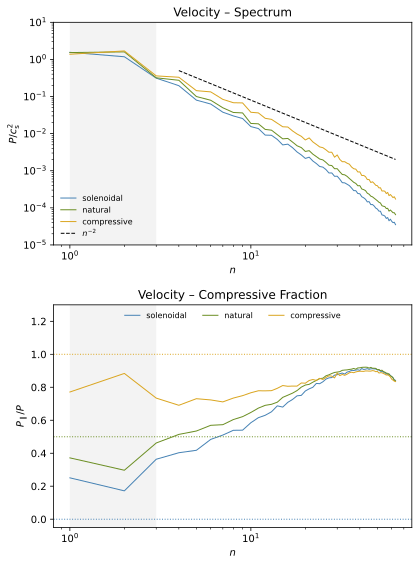

In [10]:
def spectrum(v):
    """power of a vector field summed over shells of integer wavenumber"""
    N = v.shape[1]
    n = np.fft.fftfreq(N, 1 / N)
    shell = np.rint(np.hypot(*np.meshgrid(n, n, indexing="ij"))).astype(int)
    power = np.sum(np.abs(np.fft.fft2(v))**2, axis=0) / N**4
    return np.bincount(shell.ravel(), power.ravel())

ng = np.arange(1, Np // 2)

fig, ax = plt.subplots(2, 1, figsize=(6, 8))
for zeta, col, lab in mixes:
    vs = [U[1:] / U[0] for U in runs[zeta]["snaps"]]
    assert np.isclose(np.sum(spectrum(vs[0])), np.mean(np.sum(vs[0]**2, axis=0)))
    P = np.mean([spectrum(v) for v in vs], axis=0)[ng]
    Pc = np.mean([spectrum(helmholtz(v)) for v in vs], axis=0)[ng]
    ax[0].loglog(ng, P / cs**2, "-", color=col, lw=1, label=lab)
    ax[1].semilogx(ng, Pc / P, "-", color=col, lw=1, label=lab)
    ax[1].axhline((1 - zeta)**2 / (zeta**2 + (1 - zeta)**2), color=col, ls=":", lw=1)
ax[0].loglog(ng[3:], 0.5 * mach**2 * (ng[3:] / 2.0)**-2.0, "--", color="k", lw=1, label="$n^{-2}$")
for a_ in ax:
    a_.axvspan(1, 3, color="k", alpha=0.05, lw=0)
ax[0].set(ylim=(1e-5, 10), xlabel="$n$", ylabel="$P/c_\\mathrm{s}^2$", title="Velocity – Spectrum")
ax[0].legend(fontsize=8, edgecolor="none", facecolor="none", handlelength=1.9, loc="lower left")
ax[1].set(ylim=(-0.05, 1.3), xlabel="$n$", ylabel="$P_\\parallel/P$", title="Velocity – Compressive Fraction")
ax[1].legend(fontsize=8, edgecolor="none", facecolor="none", handlelength=1.9, loc="upper center", ncol=3)

fig.tight_layout()
plt.show()

#### 4.4. Correlation Time

The correlation time of the forcing is varied from much shorter to much longer than the turnover time for the natural mixture, with the amplitude calibrated to the same Mach number in every case. A force that decorrelates quickly cannot build up a velocity along itself, so it needs a larger amplitude and works with a smaller correlation coefficient, which for a linear response grows with the square root of the correlation time in the white limit. For long correlation times the coefficient saturates, since the flow itself decorrelates from the pattern within a turnover time. The last panel shows the injection rate in units of the energy of the driving scale per turnover time, which is not the same for all runs although their Mach numbers agree, so matching the Mach number and matching the injection rate are different comparisons and the calibration offers both.

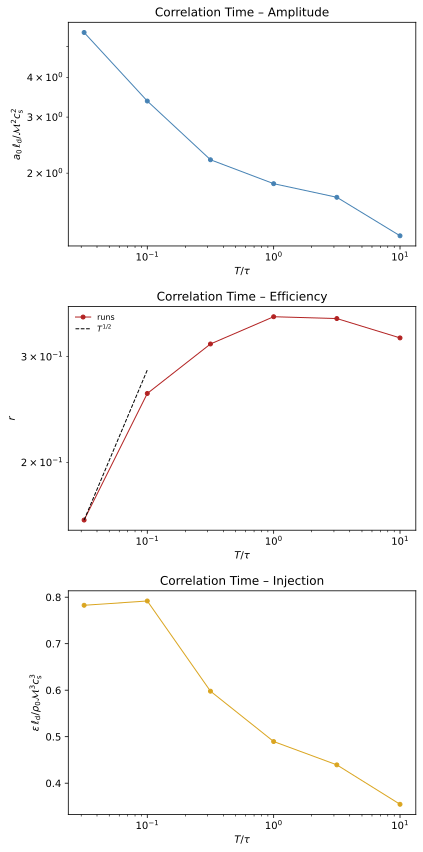

In [11]:
ratios = np.logspace(-1.5, 1, 6)
sweep = []
for q in ratios:
    make = lambda N, amp: ForcingField(N, q * tau, 0.5, amp, seed)
    amp = calibrate(make, mach, tau)
    log = run(64, make(64, amp), turns * tau)[1]
    sweep.append([amp] + [average(log, key, skip * tau) for key in ("mach", "r", "eps")])
amps, machs, corr, eps = np.array(sweep).T
assert np.max(np.abs(machs / mach - 1)) < 0.2 and corr[0] < corr[-1] and amps[0] > amps[-1]

fig, ax = plt.subplots(3, 1, figsize=(6, 12))
ax[0].loglog(ratios, amps * ld / (mach * cs)**2, "o-", color="steelblue", lw=1, ms=4)
ax[0].set(xlabel="$T/\\tau$", ylabel="$a_0\\,\\ell_\\mathrm{d}/\\mathcal{M}^2c_\\mathrm{s}^2$", title="Correlation Time – Amplitude")

ax[1].loglog(ratios, corr, "o-", color="firebrick", lw=1, ms=4, label="runs")
ax[1].loglog(ratios[:2], corr[0] * np.sqrt(ratios[:2] / ratios[0]), "--", color="k", lw=1, label="$T^{1/2}$")
ax[1].set(xlabel="$T/\\tau$", ylabel="$r$", title="Correlation Time – Efficiency")
ax[1].legend(fontsize=8, edgecolor="none", handlelength=1.9)

ax[2].semilogx(ratios, eps * ld / (rho0 * (machs * cs)**3), "o-", color="goldenrod", lw=1, ms=4)
ax[2].set(xlabel="$T/\\tau$", ylabel="$\\varepsilon\\,\\ell_\\mathrm{d}/\\rho_0\\mathcal{M}^3c_\\mathrm{s}^3$", title="Correlation Time – Injection")

fig.tight_layout()
plt.show()

#### 4.5. Evolution

The first figure shows the logarithmic density of the three matched runs at four times during and after the spin up, with one row per mixture. The second figure shows space time diagrams along a cut through the middle of the box, with the logarithmic density in the first row and the component of the forcing acceleration along the cut in the second row, both against position and time. Shocks appear as sharp fronts whose slope is their speed, and the forcing pattern changes on the correlation time, which here equals the turnover time.

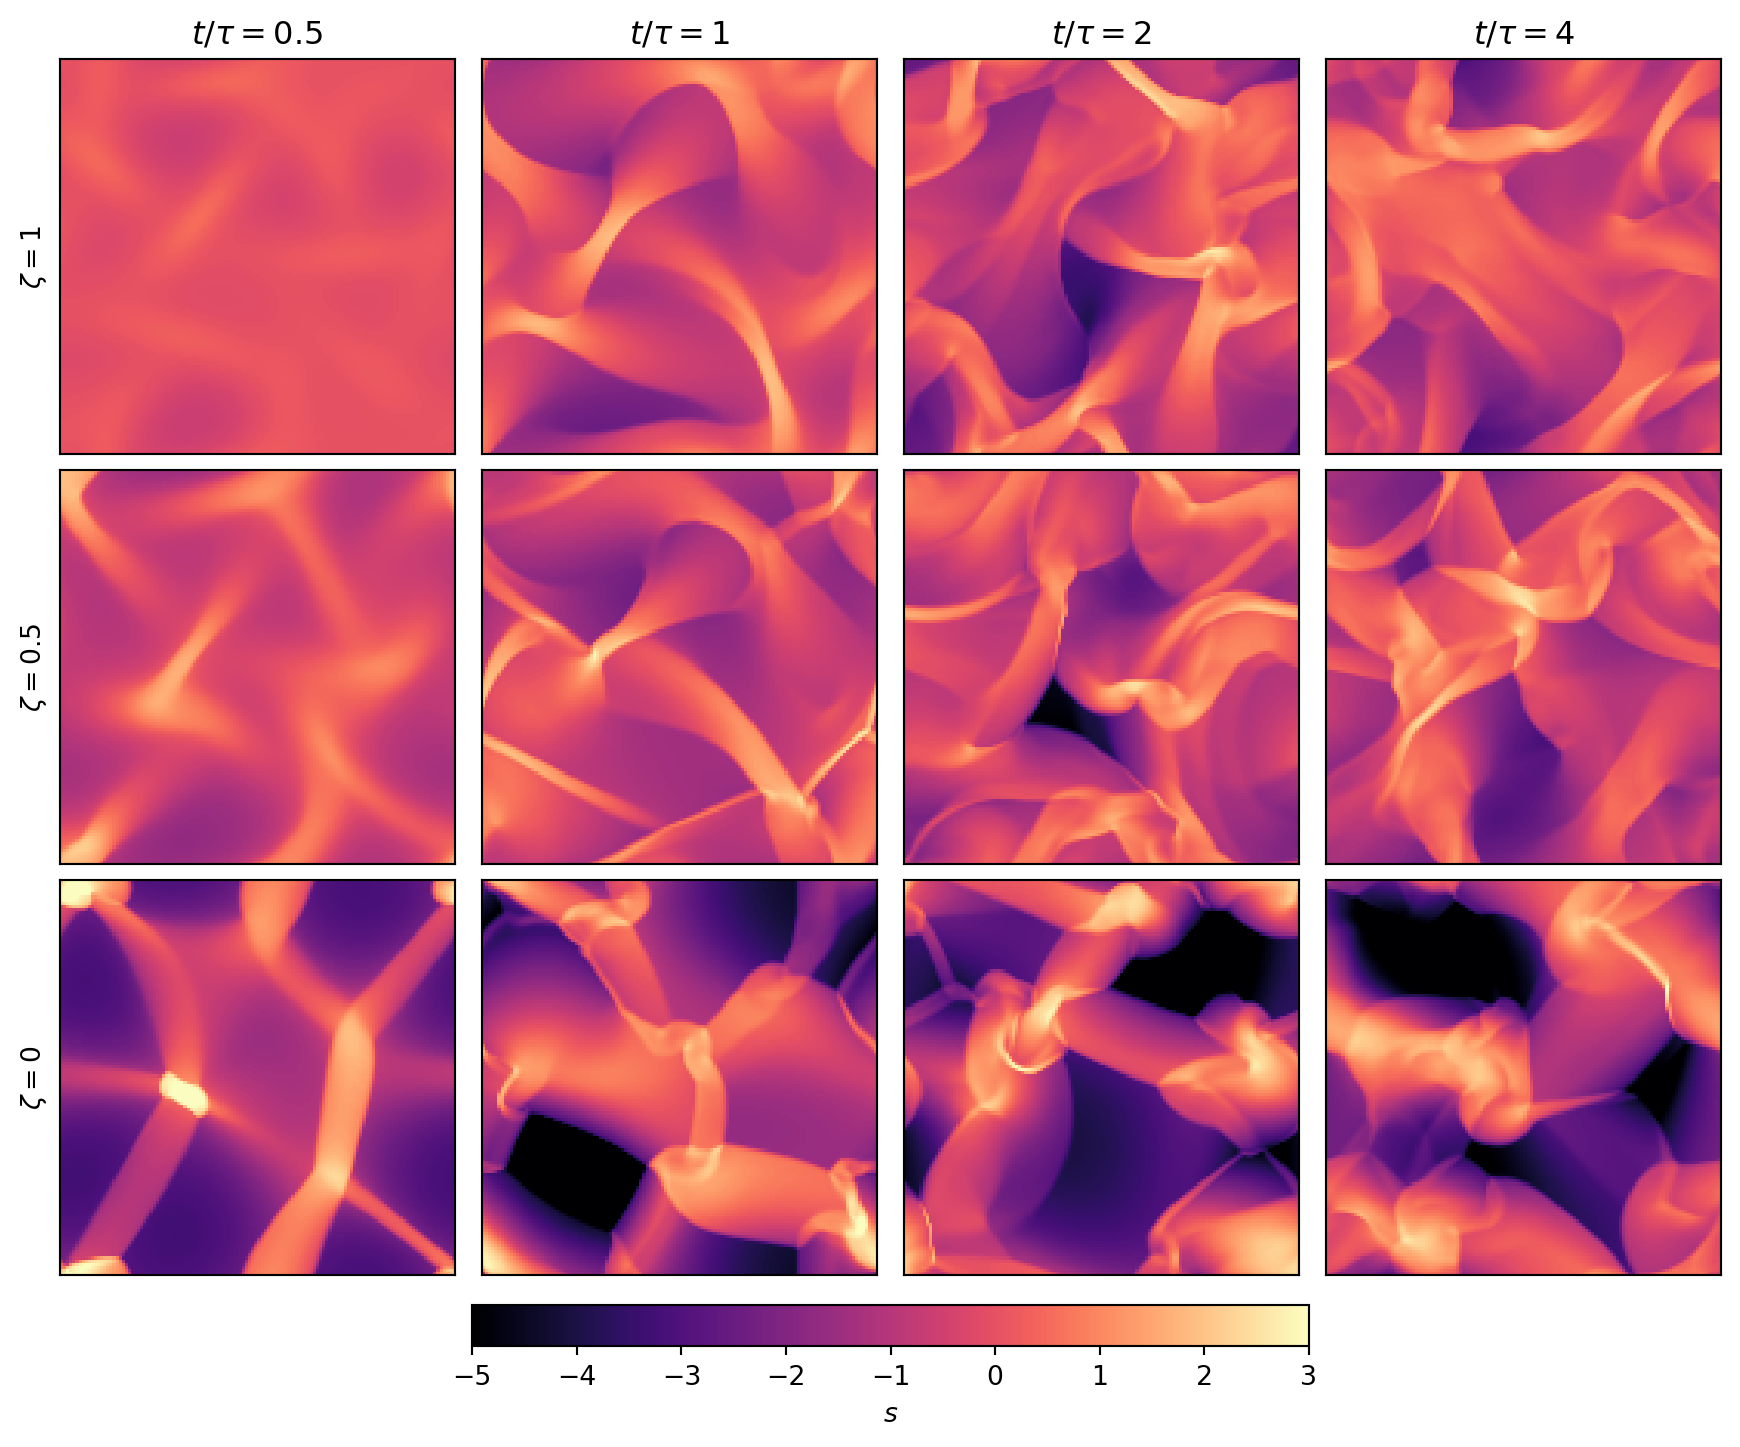

In [12]:
times = [0.5, 1, 2, 4]

fig, ax = plt.subplots(3, 4, figsize=(9, 7.4), dpi=96, layout="constrained")
for k, (zeta, _, lab) in enumerate(mixes):
    for j, tj in enumerate(times):
        U = runs[zeta]["series"][int(tj * per) - 1]
        im = ax[k, j].imshow(np.log(U[0] / rho0).T, origin="lower", extent=(0, 1, 0, 1), cmap="magma", vmin=-5, vmax=3)
        ax[k, j].set(xticks=[], yticks=[])
        ax[0, j].set_title(f"$t/\\tau = {tj:g}$")
    ax[k, 0].set_ylabel(f"$\\zeta = {zeta:g}$")
fig.colorbar(im, ax=ax, orientation="horizontal", shrink=0.5, pad=0.02, label="$s$")

%config InlineBackend.figure_formats = ["retina"]   # images embedded in svg do not display on github
plt.show()
%config InlineBackend.figure_formats = ["svg"]

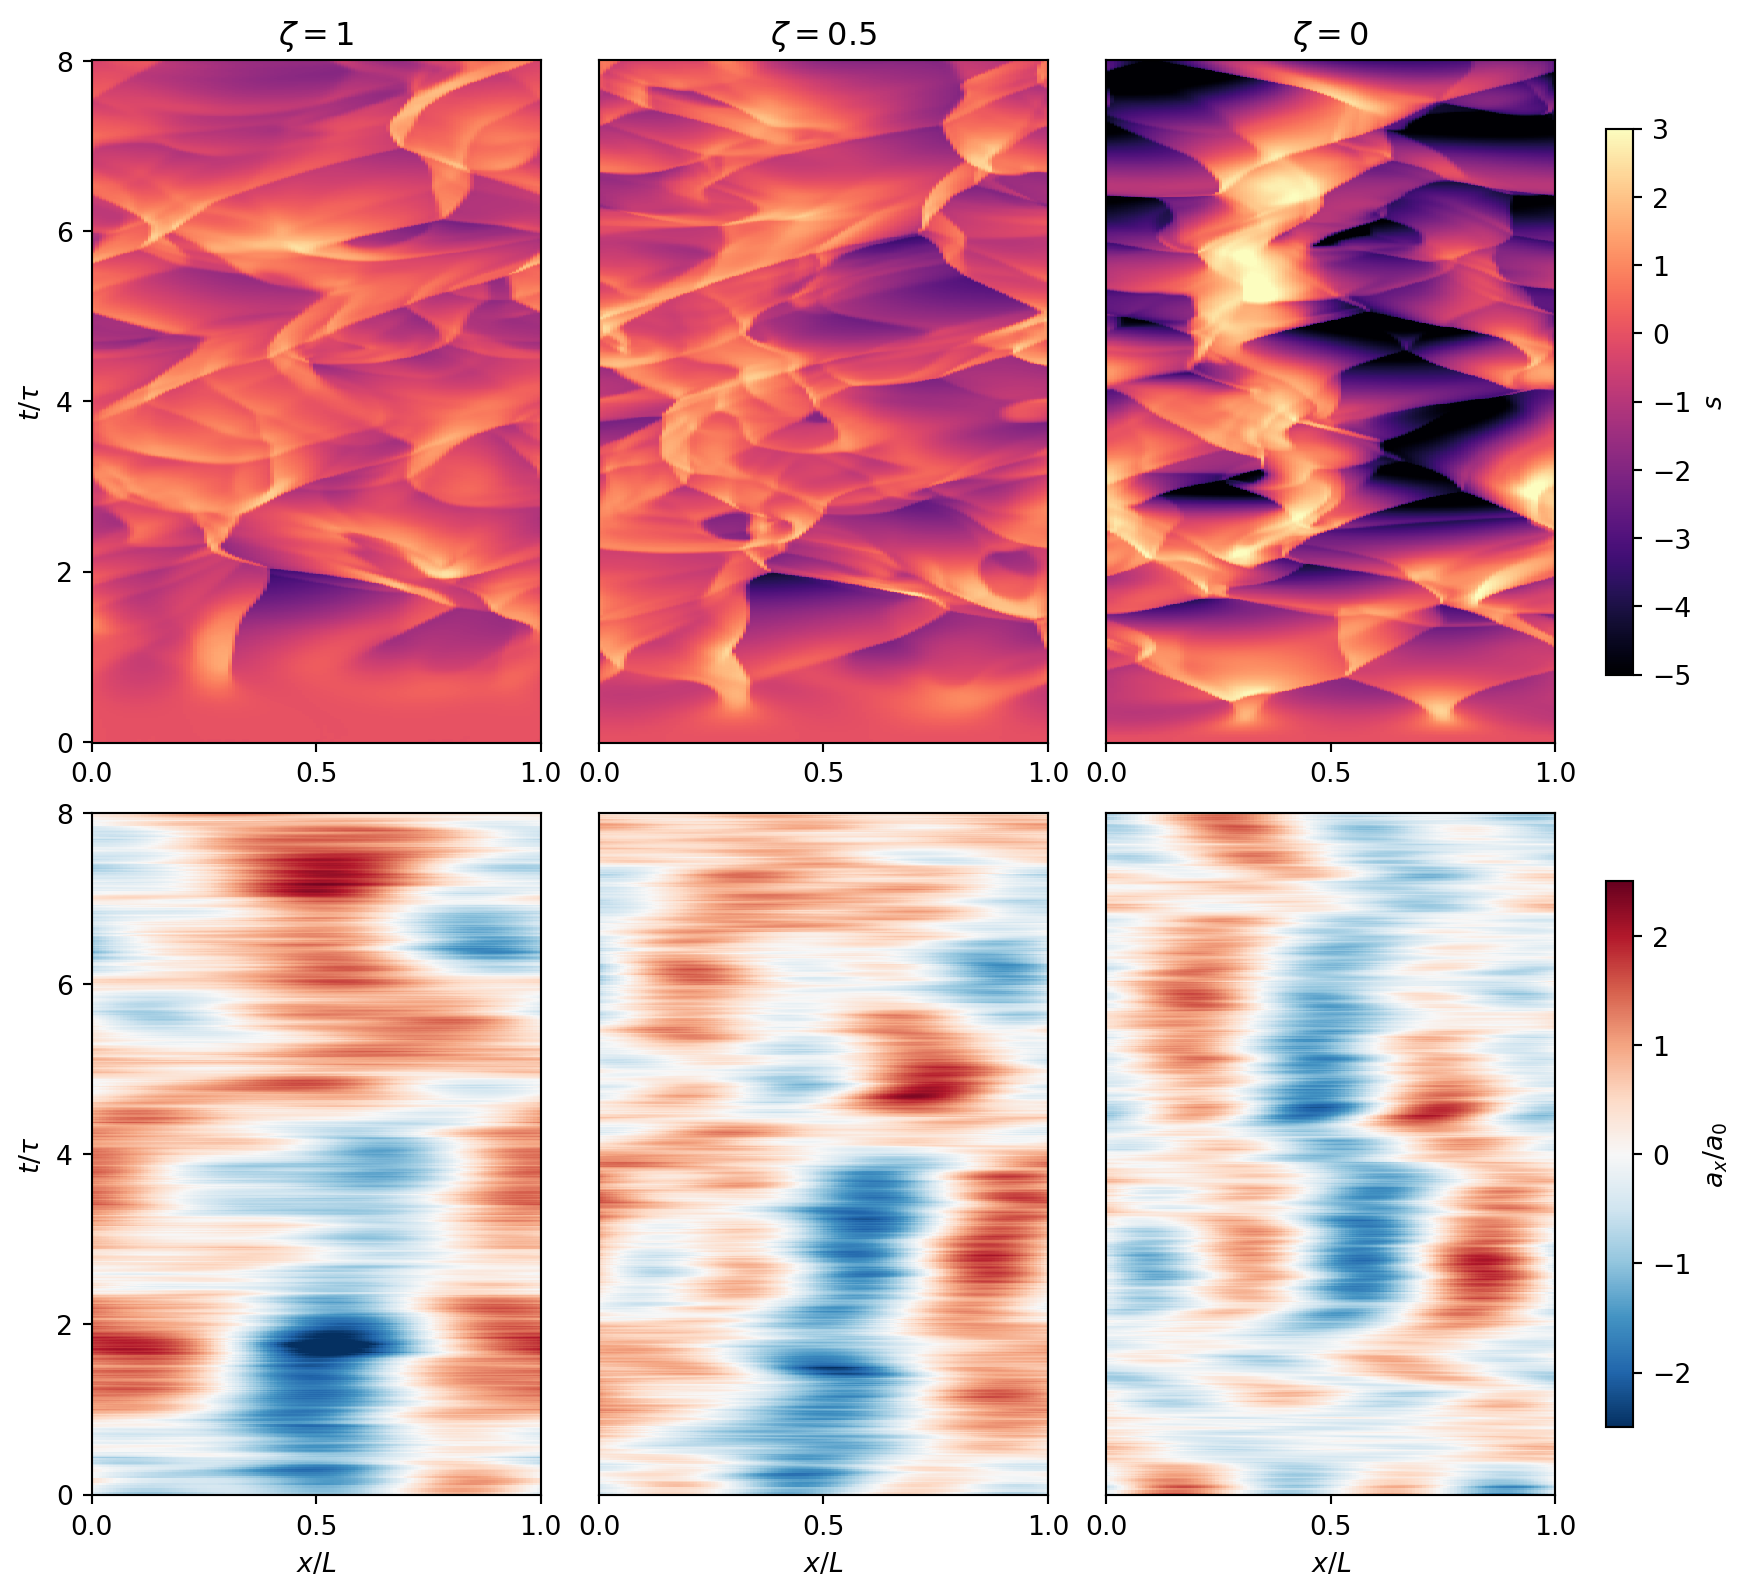

In [13]:
xg = (np.arange(Np) + 0.5) * L / Np

fig, ax = plt.subplots(2, 3, figsize=(9, 8.2), dpi=96, layout="constrained")
for k, (zeta, _, lab) in enumerate(mixes):
    log = runs[zeta]["log"]
    thin = slice(None, None, 4)                                 # every fourth step is enough for the image
    tg, cut = log["t"][thin] / tau, log["cuts"][thin]
    im0 = ax[0, k].pcolormesh(xg, tg, cut[:, 0], cmap="magma", vmin=-5, vmax=3, shading="nearest")
    im1 = ax[1, k].pcolormesh(xg, tg, cut[:, 1] / runs[zeta]["amp"], cmap="RdBu_r", vmin=-2.5, vmax=2.5, shading="nearest")
    ax[0, k].set_title(f"$\\zeta = {zeta:g}$")
    ax[1, k].set_xlabel("$x/L$")
    for a_ in ax[:, k]:
        a_.set(xticks=[0, 0.5, 1], yticks=np.arange(0, turns + 1, 2) if k == 0 else [])
for a_ in ax[:, 0]:
    a_.set_ylabel("$t/\\tau$")
fig.colorbar(im0, ax=ax[0], shrink=0.8, pad=0.02, label="$s$")
fig.colorbar(im1, ax=ax[1], shrink=0.8, pad=0.02, label="$a_x/a_0$")

%config InlineBackend.figure_formats = ["retina"]   # images embedded in svg do not display on github
plt.show()
%config InlineBackend.figure_formats = ["svg"]

#### 4.6. Mach Number

Instead of calibrating, the amplitude is varied over more than a decade for the three mixtures, with the correlation time and the duration of every run set by the estimate

$$\tau \sim \sqrt{\frac{\ell_\symup{d}}{a_0}}$$

of the turnover time from the scaling of the calibration section. The first panel shows the resulting Mach number against the amplitude with the square root as a guide, and the second panel shows the width of the logarithmic density against the measured Mach number together with the fit for every mixture as dashed lines.

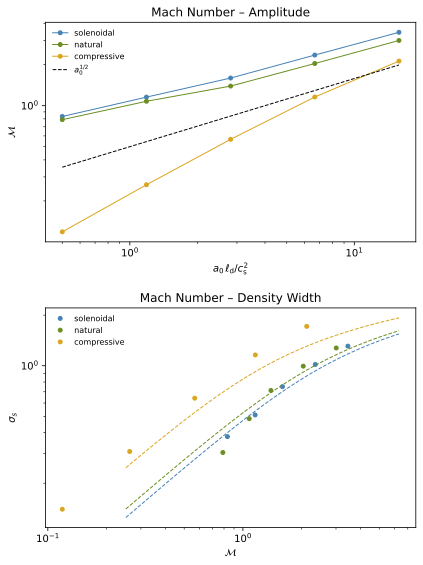

In [14]:
amps_m = np.logspace(0, 1.5, 5)
scan = {}
for zeta, _, _ in mixes:
    rows = []
    for a0 in amps_m:
        t_turn = np.sqrt(ld / a0)
        log = run(64, ForcingField(64, t_turn, zeta, a0, seed), turns * t_turn)[1]
        rows.append([average(log, key, skip * t_turn) for key in ("mach", "sigma")])
    scan[zeta] = np.array(rows).T
    assert np.all(np.diff(scan[zeta][0]) > 0)

Mg = np.logspace(-0.6, 0.8, 100)

fig, ax = plt.subplots(2, 1, figsize=(6, 8))
for zeta, col, lab in mixes:
    ax[0].loglog(amps_m * ld / cs**2, scan[zeta][0], "o-", color=col, lw=1, ms=4, label=lab)
    ax[1].loglog(scan[zeta][0], scan[zeta][1], "o", color=col, ms=4, label=lab)
    ax[1].loglog(Mg, width(zeta, Mg), "--", color=col, lw=1)
ax[0].loglog(amps_m * ld / cs**2, 0.5 * np.sqrt(amps_m * ld / cs**2), "--", color="k", lw=1, label="$a_0^{1/2}$")
ax[0].set(xlabel="$a_0\\,\\ell_\\mathrm{d}/c_\\mathrm{s}^2$", ylabel="$\\mathcal{M}$", title="Mach Number – Amplitude")
ax[0].legend(fontsize=8, edgecolor="none", handlelength=1.9, loc="upper left")
ax[1].set(xlabel="$\\mathcal{M}$", ylabel="$\\sigma_s$", title="Mach Number – Density Width")
ax[1].legend(fontsize=8, edgecolor="none", handlelength=1.9, loc="upper left")

fig.tight_layout()
plt.show()

#### 4.7. Ensemble

All runs above use a single seed, so their averages carry a statistical error from the finite duration. Repeating the run of the natural mixture at fixed amplitude and low resolution with different seeds shows this scatter directly. The first panel shows the Mach number of every member against time, and the second panel shows the time averages of the injection rate against those of the Mach number for every member, whose spread is the error that any comparison between methods at this resolution and duration has to respect.

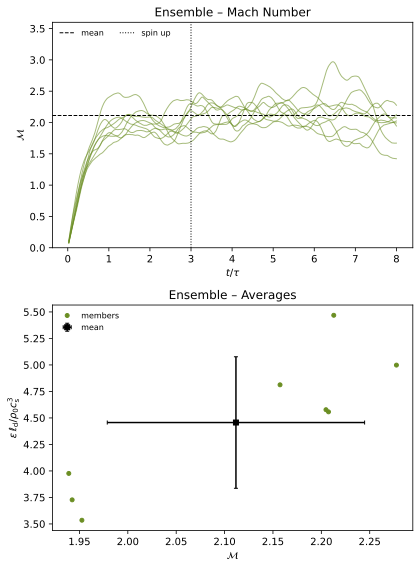

In [15]:
members = [run(64, ForcingField(64, tau, 0.5, runs[0.5]["amp"], s), turns * tau)[1] for s in range(8)]
m_avg = np.array([average(log, "mach", skip * tau) for log in members])
e_avg = np.array([average(log, "eps", skip * tau) for log in members])
assert np.std(m_avg) < 0.2 * np.mean(m_avg)

fig, ax = plt.subplots(2, 1, figsize=(6, 8))
for log in members:
    ax[0].plot(log["t"] / tau, log["mach"], "-", color="olivedrab", lw=1, alpha=0.6)
ax[0].axhline(np.mean(m_avg), color="k", ls="--", lw=1, label="mean")
ax[0].axvline(skip, color="k", ls=":", lw=1, label="spin up")
ax[0].set(ylim=(0, 3.6), xlabel="$t/\\tau$", ylabel="$\\mathcal{M}$", title="Ensemble – Mach Number")
ax[0].legend(fontsize=8, edgecolor="none", handlelength=1.9, loc="upper left", ncol=2)

unit = rho0 * cs**3 / ld
ax[1].errorbar(np.mean(m_avg), np.mean(e_avg) / unit, xerr=np.std(m_avg), yerr=np.std(e_avg) / unit, fmt="s", color="k", ms=5,
               capsize=2, label="mean")
ax[1].plot(m_avg, e_avg / unit, "o", color="olivedrab", ms=4, label="members")
ax[1].set(xlabel="$\\mathcal{M}$", ylabel="$\\varepsilon\\,\\ell_\\mathrm{d}/\\rho_0c_\\mathrm{s}^3$", title="Ensemble – Averages")
ax[1].legend(fontsize=8, edgecolor="none", handlelength=1.9, loc="upper left")

fig.tight_layout()
plt.show()

### 5. Methods

#### 5.1. Second Order

The acceleration of the first order process is continuous but not differentiable in time, and its spectrum falls only with the square of the frequency. A second order process replaces every amplitude by a damped oscillator that is driven by white noise $\eta$ with the natural frequency $\omega_0$ and the damping ratio $\delta$

$$\ddot{g} + 2\delta\omega_0\,\dot{g} + \omega_0^2\,g = \eta \qquad S(\omega) \propto \frac{1}{(\omega_0^2 - \omega^2)^2 + 4\delta^2\omega_0^2\omega^2}$$

which gives a differentiable acceleration whose spectrum $S$ falls with the fourth power of the frequency. The integral time follows from the spectrum at zero frequency and from the variance $C(0)$ of the process

$$T = \frac{S(0)}{2C(0)} = \frac{2\delta}{\omega_0}$$

so the choice $\omega_0 = 2\delta/T$ keeps the integral time of the first order process while the damping ratio sets the shape of the correlation, which oscillates for weak damping, decays fastest at critical damping with $\delta = 1$ and approaches the first order process for strong damping. In state space form with $\mathbf{x} = (g, \dot{g})$ and the drift matrix $\mathsf{A}$ of the oscillator the exact update over a step is

$$\mathbf{x}^{n+1} = \mathsf{\Phi}\,\mathbf{x}^n + \mathsf{Q}^{1/2}\boldsymbol{\xi} \qquad \mathsf{\Phi} = e^{\mathsf{A}\Delta t} \qquad \mathsf{Q} = \mathsf{P} - \mathsf{\Phi}\,\mathsf{P}\,\mathsf{\Phi}^\top$$

with the stationary covariance $\mathsf{P}$ which is diagonal, with the variance of the amplitude and with $\omega_0^2$ times that variance for its derivative, and where the noise covariance $\mathsf{Q}$ follows from demanding that the update leaves the stationary covariance unchanged.

#### 5.2. Limits

Two limits of the first order process bracket the range of correlation times. A frozen pattern is the limit of an infinite correlation time, where the exact update leaves the amplitudes unchanged. In the white limit the correlation time is shorter than any step, so every step draws a new pattern $\hat{\mathbf{a}}$ of unit root mean square, and the acceleration has to grow with the inverse square root of the step size through a strength $a_\symup{w}$ to keep a finite effect

$$\mathbf{a} = \frac{a_\symup{w}}{\sqrt{\Delta t}}\,\hat{\mathbf{a}} \qquad \varepsilon \approx \frac{\rho_0\,a_\symup{w}^2}{2}$$

where the injection rate follows from the energy of the kick alone, since a new pattern is not correlated with the flow.

#### 5.3. Fixed Power

The injection rate of all methods so far fluctuates, since the work depends on the momentary alignment of force and flow. In the style of [Alvelius 1999] the white forcing can instead inject a prescribed rate $\varepsilon$ exactly. Removing the part of the pattern that is correlated with the momentum

$$\mathbf{a}^\prime = \hat{\mathbf{a}} - \frac{\langle\rho\,\mathbf{v}\cdot\hat{\mathbf{a}}\rangle}{\langle\rho\,\mathbf{v}^2\rangle}\,\mathbf{v}$$

leaves only the energy of the kick itself in the kick energy of the coupling section, and scaling the result until

$$\frac{\Delta t}{2}\,\langle\rho\,\mathbf{a}^2\rangle = \varepsilon$$

holds fixes the injection rate in advance, which makes it the control parameter in place of an amplitude.

#### 5.4. Real Space

Driving in Fourier space is homogeneous and Gaussian by construction, while physical sources such as supernovae are localized. As a toy for such sources, blasts switch on at random positions $\mathbf{x}_b$ with a constant rate, last for a fixed time and push the gas radially outwards within a radius $R$ around their centre

$$\mathbf{a}(\mathbf{x}) = a_0 \sum_b \frac{\mathbf{x} - \mathbf{x}_b}{R}\,\exp\left(-\frac{|\mathbf{x} - \mathbf{x}_b|^2}{2R^2}\right)$$

which is a gradient field and therefore purely compressive, but intermittent in space and time and not Gaussian.

[Alvelius 1999]: https://doi.org/10.1063/1.870050

In [16]:
class SecondOrderField(ForcingField):
    """forcing with a damped oscillator per amplitude, set by integral time and damping ratio"""

    def __init__(self, N, T, zeta, amp, seed, damping=1.0):
        super().__init__(N, T, zeta, amp, seed)
        w0 = 2 * damping / T
        self.A = np.array([[0.0, 1.0], [-w0**2, -2 * damping * w0]])
        self.P0 = np.diag([1.0, w0**2])                         # stationary covariance for unit variance
        self.x = np.stack([self.g, w0 * self.s[:, None] * self._draw(1)])

    def step(self, dt):
        """exact update of amplitudes and their derivatives over one step"""
        Phi = sc.linalg.expm(self.A * dt)
        w, V = np.linalg.eigh(self.P0 - Phi @ self.P0 @ Phi.T)
        root = V * np.sqrt(np.maximum(w, 0))
        self.count += 1
        xi = np.stack([self._draw(2 * self.count), self._draw(2 * self.count + 1)])
        self.x = np.einsum("ij,jkc->ikc", Phi, self.x) + self.s[:, None] * np.einsum("ij,jkc->ikc", root, xi)
        self.g = self.x[0]

class WhiteField(ForcingField):
    """forcing that is white in time, amp is the strength of the noise"""

    def __init__(self, N, zeta, amp, seed):
        super().__init__(N, 1.0, zeta, amp, seed)

    def step(self, dt):
        """new pattern for every step"""
        self.count += 1
        self.g = self.s[:, None] * self._draw(self.count)

    def accel(self, U=None, dt=1.0):
        """pattern scaled with the inverse square root of the step size"""
        return super().accel() / np.sqrt(dt)

class PowerField(WhiteField):
    """white forcing without correlation to the flow, amp is the injection rate"""

    def accel(self, U, dt):
        """pattern orthogonal to the momentum and scaled to the prescribed power"""
        a = momentum_free(super().accel(U, dt), U[0])
        a = a - np.mean(np.sum(U[1:] * a, axis=0)) / (np.mean(np.sum(U[1:]**2, axis=0) / U[0]) + 1e-300) * U[1:] / U[0]
        return a * np.sqrt(2 * self.amp / (dt * np.mean(U[0] * np.sum(a**2, axis=0))))

class BlastField:
    """localized radial pushes that switch on at a constant rate and last for a fixed time"""

    def __init__(self, N, T, rate, radius, amp, seed):
        self.x = (np.arange(N) + 0.5) * L / N
        self.T, self.rate, self.radius, self.amp, self.seed = T, rate, radius, amp, seed
        self.t, self.count = 0.0, 0
        rng = np.random.default_rng([seed, 0])                  # stationary start with random ages
        self.events = [(T * rng.random(), self._pattern(L * rng.random(2))) for _ in range(rng.poisson(rate * T))]

    def _pattern(self, centre):
        """radial profile around centre with periodic distances"""
        dx, dy = np.meshgrid(*[(self.x - c + 0.5 * L) % L - 0.5 * L for c in centre], indexing="ij")
        return np.stack([dx, dy]) / self.radius * np.exp(-0.5 * (dx**2 + dy**2) / self.radius**2)

    def step(self, dt):
        """remove expired blasts and draw new ones"""
        self.count += 1
        self.t += dt
        rng = np.random.default_rng([self.seed, self.count])
        self.events = [e for e in self.events if e[0] > self.t]
        self.events += [(self.t + self.T, self._pattern(L * rng.random(2))) for _ in range(rng.poisson(self.rate * dt))]

    def accel(self, U=None, dt=None):
        """sum over all active blasts"""
        return self.amp * sum((p for _, p in self.events), np.zeros((2, len(self.x), len(self.x))))

#### 5.5. Tests

The tests check the stationary variance, the correlation at a fixed lag and the integral time of the second order process for critical and for weak damping, the injection rate of the white forcing against its estimate, that the fixed power forcing holds its injection rate with much smaller fluctuations than the first order process, and that the blasts are free of vorticity. All methods are then calibrated to the same Mach number at low resolution. The first order process enters with the purely solenoidal, the natural and the purely compressive mixture, all other methods in Fourier space use the natural mixture, and the blasts are purely compressive by construction. The first panel shows the correlation coefficient against the injection rate in units of the energy of the driving scale per turnover time, and the second panel shows the width of the logarithmic density against the compressive fraction of the velocity power. The last two panels show the injection rate averaged over short windows and the Mach number against time for four of the methods. The three figures below them show the logarithmic density with the forcing as arrows, the divergence and the vorticity at the end of the run for every method, in the same units as the maps of the matched runs.

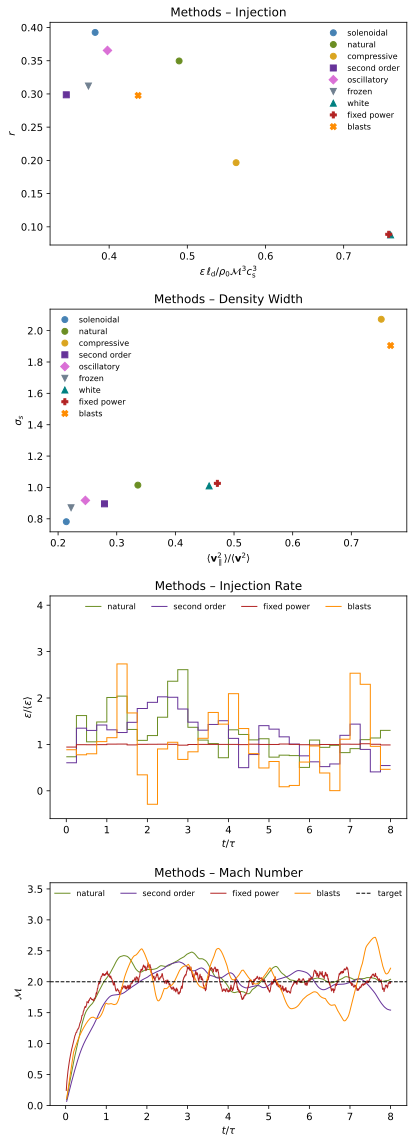

In [17]:
dt_t, n_t, lag = 0.05, 20000, 10
for damping in (1.0, 0.3):
    f = SecondOrderField(8, 1.0, 0.5, 1.0, seed, damping)
    G = np.empty((n_t,) + f.g.shape, dtype=complex)
    for i in range(n_t):
        G[i] = f.g / f.s[:, None]
        f.step(dt_t)
    X = np.concatenate([G.real, G.imag], axis=1).reshape(n_t, -1)
    acf = np.array([np.mean(X[:n_t - j] * X[j:]) for j in range(400)]) / np.mean(X**2)
    w0 = 2 * damping
    wd = w0 * np.sqrt(max(1 - damping**2, 1e-12))               # critical damping as limit
    decay = np.exp(-damping * w0 * lag * dt_t)
    exact = decay * (np.cos(wd * lag * dt_t) + damping * w0 / wd * np.sin(wd * lag * dt_t))
    assert abs(np.mean(X**2) - 1) < 0.05 and abs(acf[lag] - exact) < 0.02 and abs(dt_t * (np.sum(acf) - 0.5) - 1) < 0.1

log_w = run(64, WhiteField(64, 0.5, 3.0, seed), turns * tau)[1]
assert abs(average(log_w, "eps", skip * tau) / (0.5 * rho0 * 3.0**2) - 1) < 0.25
div, rot = derivatives(np.concatenate([np.ones((1, 64, 64)), BlastField(64, tau, 4 / tau, L / 8, 1.0, seed).accel()]))
assert np.sqrt(np.mean(rot**2)) < 0.05 * np.sqrt(np.mean(div**2))

methods = [("solenoidal", "steelblue", "o", 10.0, lambda N, amp: ForcingField(N, tau, 1.0, amp, seed)),
           ("natural", "olivedrab", "o", 10.0, lambda N, amp: ForcingField(N, tau, 0.5, amp, seed)),
           ("compressive", "goldenrod", "o", 30.0, lambda N, amp: ForcingField(N, tau, 0.0, amp, seed)),
           ("second order", "rebeccapurple", "s", 10.0, lambda N, amp: SecondOrderField(N, tau, 0.5, amp, seed)),
           ("oscillatory", "orchid", "D", 10.0, lambda N, amp: SecondOrderField(N, tau, 0.5, amp, seed, 0.3)),
           ("frozen", "slategray", "v", 10.0, lambda N, amp: ForcingField(N, np.inf, 0.5, amp, seed)),
           ("white", "teal", "^", 3.5, lambda N, amp: WhiteField(N, 0.5, amp, seed)),
           ("fixed power", "firebrick", "P", 7.0, lambda N, amp: PowerField(N, 0.5, amp, seed)),
           ("blasts", "darkorange", "X", 40.0, lambda N, amp: BlastField(N, tau, 4 / tau, L / 8, amp, seed))]

compare = {}
for name, _, _, guess, make in methods:
    amp = calibrate(make, mach, tau, amp=guess)
    field = make(64, amp)
    U, log, snaps = run(64, field, turns * tau, snap_dt=tau / per)
    vs = [Us[1:] / Us[0] for Us in snaps[skip * per:]]
    late = log["t"] > skip * tau
    compare[name] = {"log": log, "U": U, "accel": field.accel(U, log["dt"][-1]),
                     "chi": np.mean([np.sum(helmholtz(v)**2) / np.sum(v**2) for v in vs]),
                     "noise": np.std(log["eps"][late]) / np.mean(log["eps"][late])}
    compare[name].update({key: average(log, key, skip * tau) for key in ("mach", "eps", "r", "sigma")})
    assert abs(compare[name]["mach"] / mach - 1) < 0.25
assert compare["fixed power"]["noise"] < 0.2 * compare["natural"]["noise"]

fig, ax = plt.subplots(4, 1, figsize=(6, 16))
for name, col, mark, _, _ in methods:
    c = compare[name]
    ax[0].plot(c["eps"] * ld / (rho0 * (c["mach"] * cs)**3), c["r"], mark, color=col, ms=6, label=name)
    ax[1].plot(c["chi"], c["sigma"], mark, color=col, ms=6, label=name)
ax[0].set(xlabel="$\\varepsilon\\,\\ell_\\mathrm{d}/\\rho_0\\mathcal{M}^3c_\\mathrm{s}^3$", ylabel="$r$", title="Methods – Injection")
ax[1].set(xlabel="$\\langle\\mathbf{v}_\\parallel^2\\rangle/\\langle\\mathbf{v}^2\\rangle$", ylabel="$\\sigma_s$", title="Methods – Density Width")

edges_t = np.linspace(0, turns * tau, 4 * turns + 1)
for name, col, mark, _, _ in methods:
    if name in ("natural", "second order", "fixed power", "blasts"):
        log = compare[name]["log"]
        injected = np.interp(edges_t, log["t"], np.cumsum(log["eps"] * log["dt"]))
        ax[2].stairs(np.diff(injected) / np.diff(edges_t) / compare[name]["eps"], edges_t / tau, baseline=None, color=col, lw=1, label=name)
        ax[3].plot(log["t"] / tau, log["mach"], "-", color=col, lw=1, label=name)
ax[2].set(ylim=(-0.6, 4.2), xlabel="$t/\\tau$", ylabel="$\\varepsilon/\\langle\\varepsilon\\rangle$", title="Methods – Injection Rate")
ax[3].axhline(mach, color="k", ls="--", lw=1, label="target")
ax[3].set(ylim=(0, 3.6), xlabel="$t/\\tau$", ylabel="$\\mathcal{M}$", title="Methods – Mach Number")
ax[0].legend(fontsize=8, edgecolor="none", handlelength=1.9, loc="upper right")
ax[1].legend(fontsize=8, edgecolor="none", handlelength=1.9, loc="upper left")
ax[2].legend(fontsize=8, edgecolor="none", handlelength=1.9, loc="upper center", ncol=4)
ax[3].legend(fontsize=8, edgecolor="none", handlelength=1.9, loc="upper center", ncol=5)

fig.tight_layout()
plt.show()

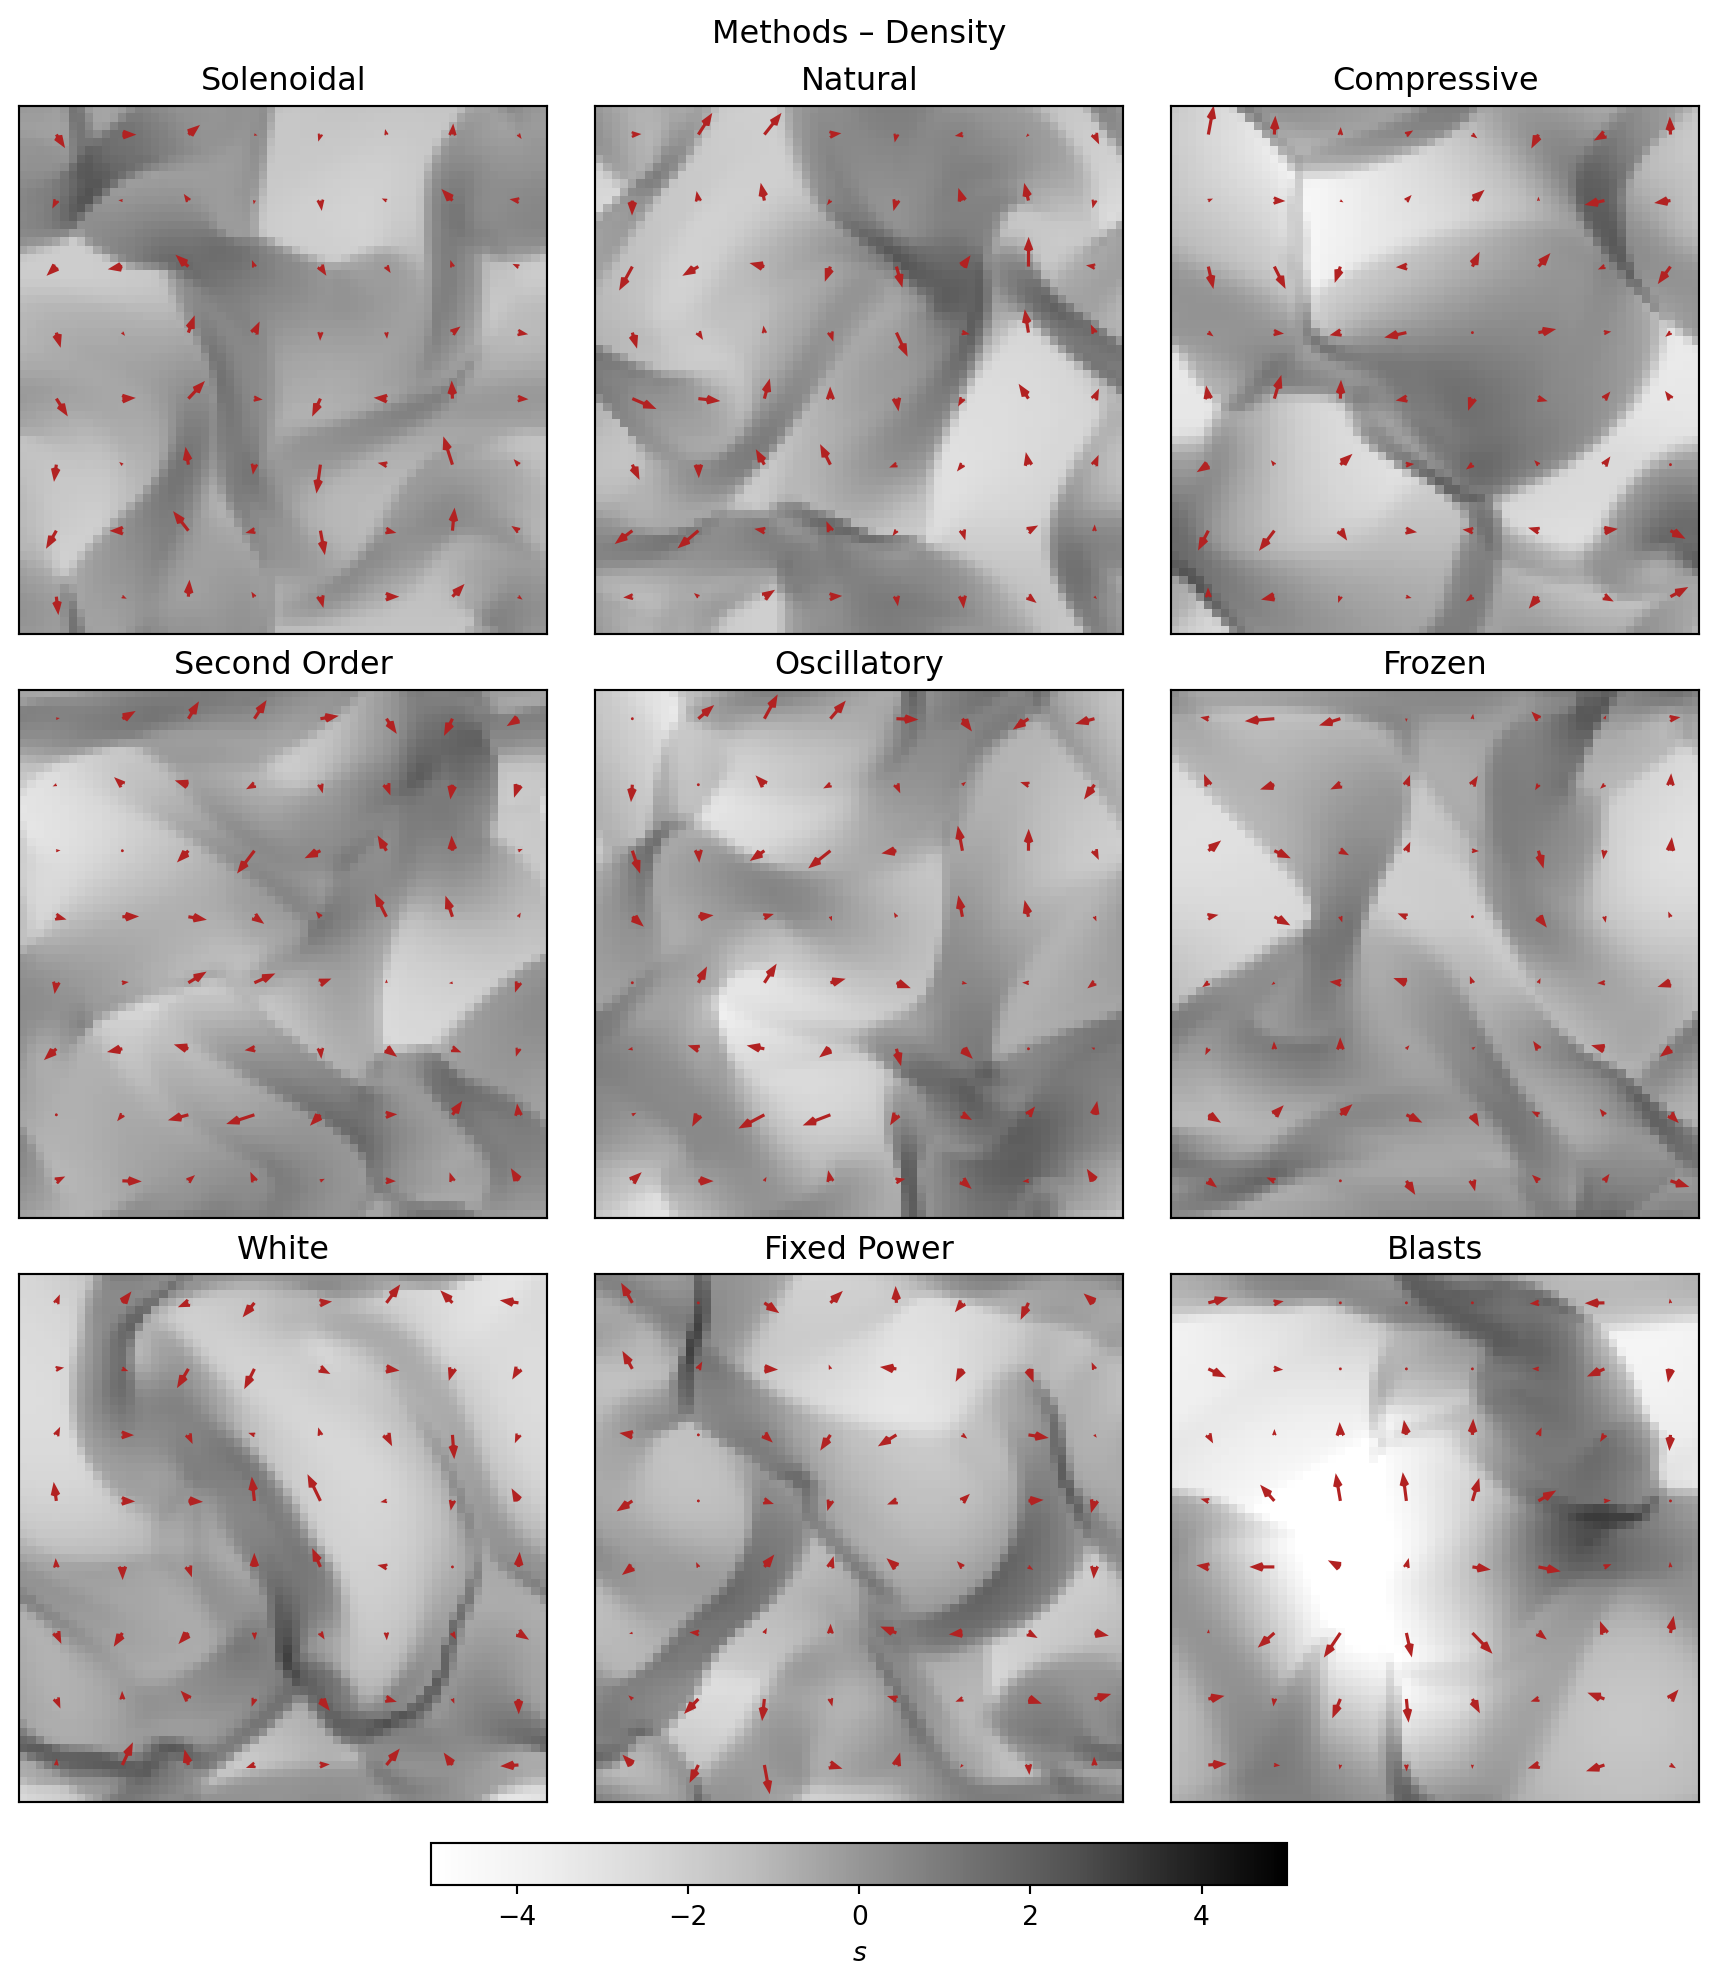

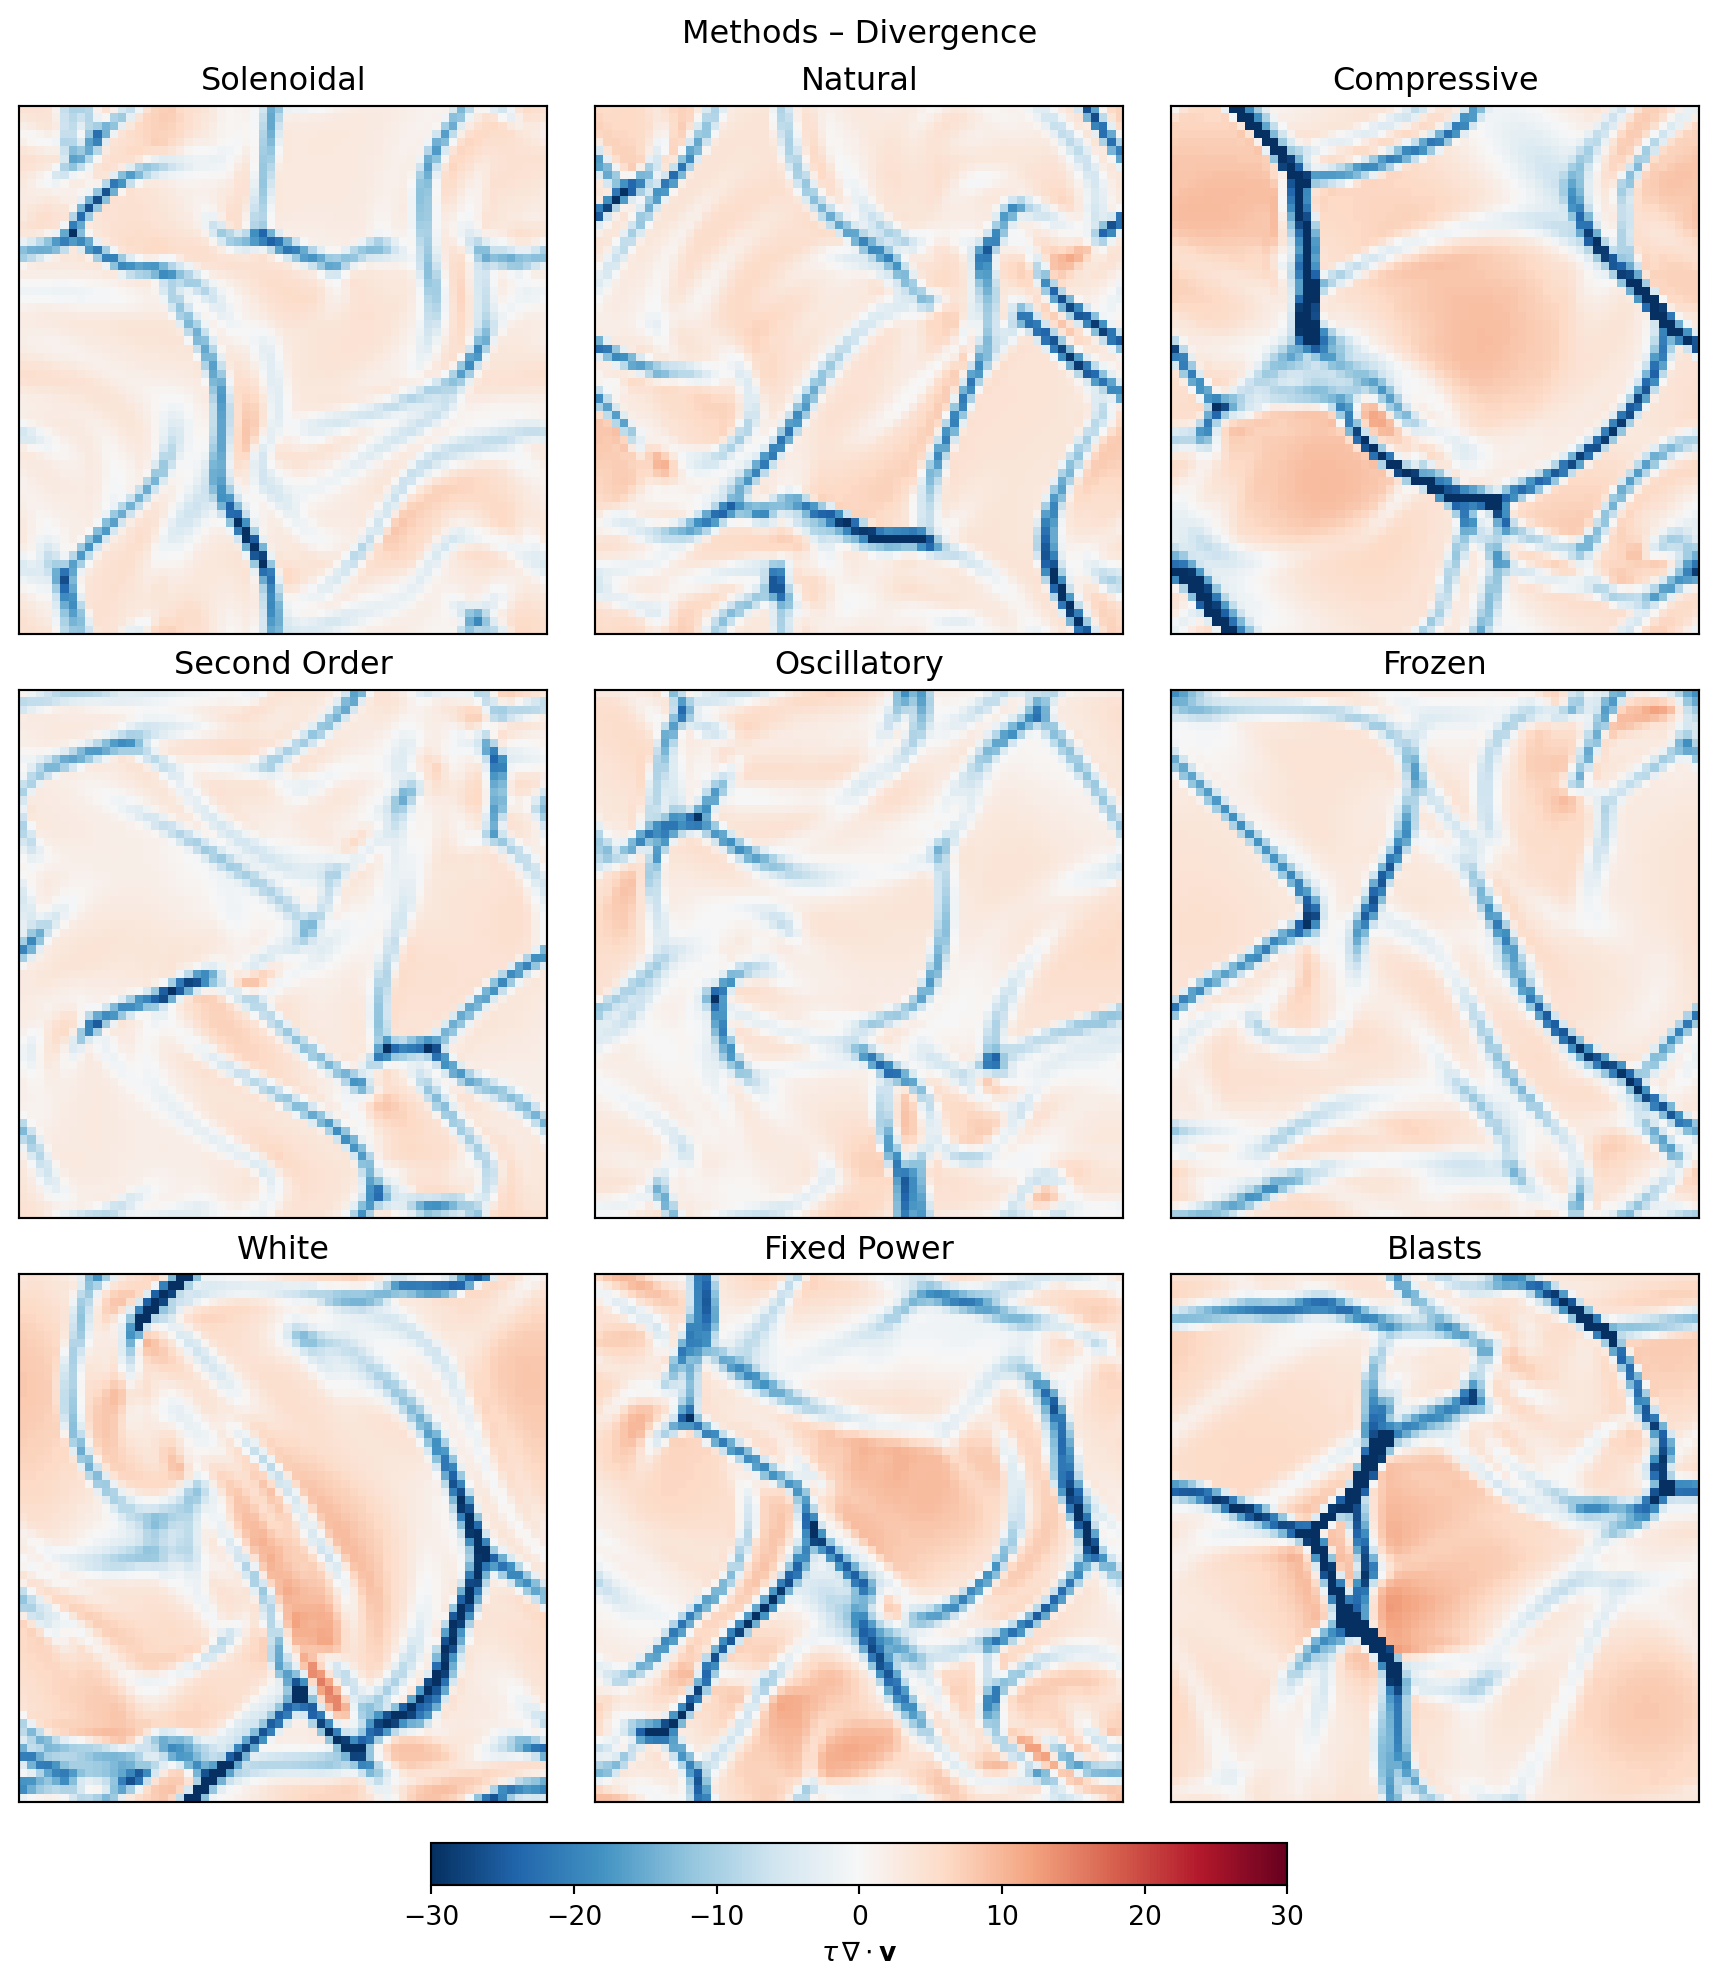

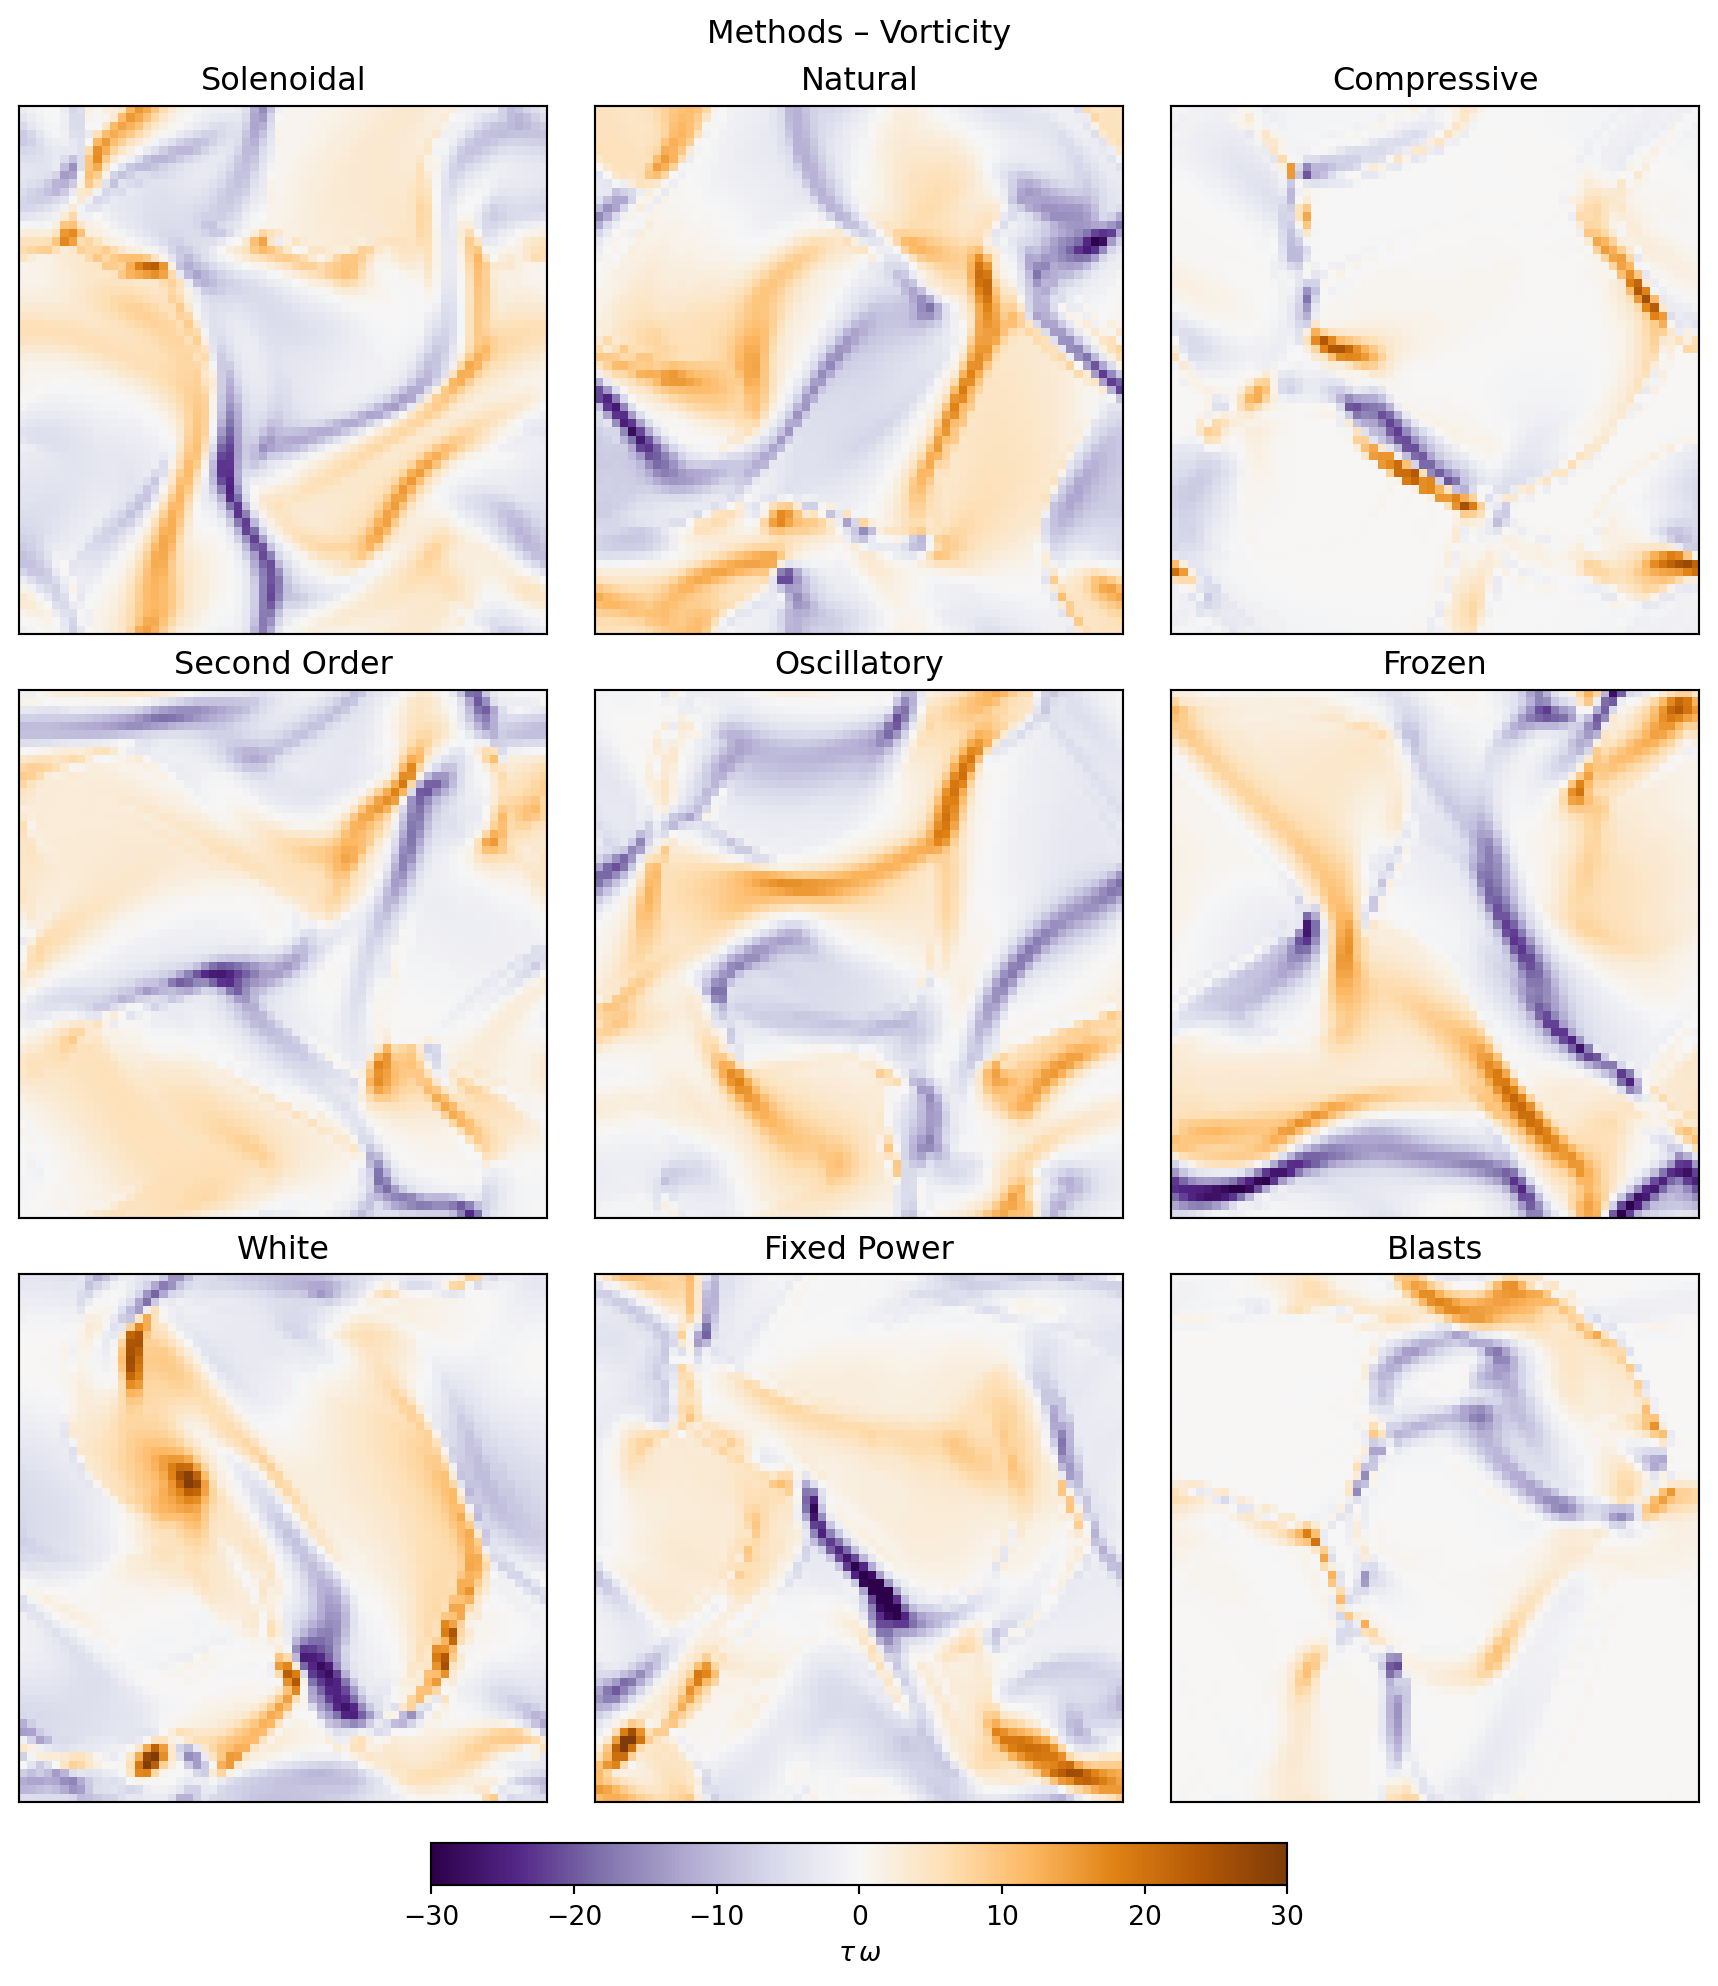

In [18]:
every = 8                                                       # arrows on a coarse regular grid
pick = np.arange(every // 2, 64, every)
xa = (pick + 0.5) * L / 64
panels = [("Methods – Density", "Greys", 5, "$s$"), ("Methods – Divergence", "RdBu_r", 30, "$\\tau\\,\\nabla\\cdot\\mathbf{v}$"),
          ("Methods – Vorticity", "PuOr_r", 30, "$\\tau\\,\\omega$")]

%config InlineBackend.figure_formats = ["retina"]   # images embedded in svg do not display on github
for q, (title, cmap, lim, lab) in enumerate(panels):
    fig, ax = plt.subplots(3, 3, figsize=(9, 10.2), dpi=96, layout="constrained")
    for a_, (name, _, _, _, _) in zip(ax.ravel(), methods):
        U = compare[name]["U"]
        image = np.log(U[0] / rho0) if q == 0 else derivatives(U)[q - 1] * tau
        im = a_.imshow(image.T, origin="lower", extent=(0, 1, 0, 1), cmap=cmap, vmin=-lim, vmax=lim)
        if q == 0:
            a = compare[name]["accel"][:, pick][:, :, pick]
            a_.quiver(*np.meshgrid(xa, xa, indexing="ij"), a[0], a[1], color="firebrick", width=0.006, headwidth=3, headlength=4,
                      angles="xy", scale_units="xy", scale=np.max(np.hypot(a[0], a[1])) / (0.45 * every / 64))
        a_.set(xticks=[], yticks=[], title=name.title())
    fig.suptitle(title)
    fig.colorbar(im, ax=ax, orientation="horizontal", shrink=0.5, pad=0.02, label=lab)
    plt.show()
%config InlineBackend.figure_formats = ["svg"]

### 6. Energy Equation

#### 6.1. Equations

With an energy equation the state gains the total energy density $e = p/(\gamma - 1) + \rho\,\mathbf{v}^2/2$ of an ideal gas with the adiabatic index $\gamma$ and the forced system contains

$$\partial_t e + \nabla\cdot\left[(e + p)\,\mathbf{v}\right] = \rho\,\mathbf{v}\cdot\mathbf{a}$$

next to the equations for mass and momentum, where the pressure takes the place of $c_\symup{s}^2\rho$ in the momentum flux. The same reconstruction and the same flux with two waves apply, with the signal speeds $v \pm c$ of the local sound speed $c$ from

$$c^2 = \frac{\gamma\,p}{\rho}$$

and the gas starts at rest with the pressure that gives the sound speed of the isothermal runs.

#### 6.2. Kick

A kick of the momentum at fixed density over a step changes the kinetic energy by the kick energy of the coupling section, so a consistent update adds the same amount to the total energy

$$\Delta e = \Delta t\,\rho\,\mathbf{v}\cdot\mathbf{a} + \frac{\Delta t^2}{2}\,\rho\,\mathbf{a}^2$$

and leaves the thermal energy untouched. An update that only adds the work with the velocity before the kick misses the second term, and since the kinetic energy still grows by the full amount, the difference is taken from the thermal energy

$$\Delta e_\symup{th} = -\frac{\Delta t^2}{2}\,\rho\,\mathbf{a}^2$$

in every step, which cools the gas at a rate that is proportional to the step size. This is the drift that a comment in the module `ApplyExtForceGas` of SHAMROCK estimates for its midpoint coupling, which uses a momentum without the kick, and marks as still to be confirmed, while the trapezoidal coupling in the module `ApplyExtForceGasTrapezoidal` includes the kick in the momentum at the end of the step.

In [19]:
gamma = 5.0 / 3.0

def primitive(U):
    """density, velocity and pressure from conserved variables with energy"""
    W = U.copy()
    W[1:3] /= U[0]
    W[3] = (gamma - 1) * (U[3] - 0.5 * np.sum(U[1:3]**2, axis=0) / U[0])
    return W

def hll_energy(W, ax):
    """flux through upper faces along axis with energy equation"""
    s = 0.5 * slopes(W, ax)
    sides = []
    for Wf in (W + s, np.roll(W - s, -1, ax)):
        rho, v, p = Wf[0], Wf[ax], Wf[3]
        Uf = np.stack([rho, rho * Wf[1], rho * Wf[2], p / (gamma - 1) + 0.5 * rho * (Wf[1]**2 + Wf[2]**2)])
        Ff = Uf * v
        Ff[ax] += p
        Ff[3] += p * v
        sides.append((Uf, Ff, v - np.sqrt(gamma * p / rho), v + np.sqrt(gamma * p / rho)))
    (UL, FL, loL, hiL), (UR, FR, loR, hiR) = sides
    SL, SR = np.minimum(np.minimum(loL, loR), 0), np.maximum(np.maximum(hiL, hiR), 0)
    return (SR * FL - SL * FR + SL * SR * (UR - UL)) / (SR - SL)

def energy_step(U, dt, dx):
    """two stage step with energy equation"""
    def rhs_energy(U):
        W = primitive(U)
        fx, fy = hll_energy(W, 1), hll_energy(W, 2)
        return (np.roll(fx, 1, 1) - fx + np.roll(fy, 1, 2) - fy) / dx
    U1 = U + dt * rhs_energy(U)
    return 0.5 * (U + U1 + dt * rhs_energy(U1))

def run_energy(N, forcing, t_end, centred=True, C=0.4):
    """driven adiabatic run from rest with one full kick per step, returns log"""
    dx = L / N
    U = np.zeros((4, N, N))
    U[0], U[3] = rho0, rho0 * cs**2 / (gamma * (gamma - 1))
    t, drift, log = 0.0, 0.0, []
    while t < t_end * (1 - 1e-12):
        W = primitive(U)
        dt = C * dx / np.max(np.abs(W[1:3]) + np.sqrt(gamma * W[3] / W[0]))
        a = momentum_free(forcing.accel(U, dt), U[0])
        dt = min(dt, C * np.sqrt(dx / (np.max(np.abs(a)) + 1e-300)), t_end - t)
        U = energy_step(U, dt, dx)
        U[3] += dt * np.sum(U[1:3] * a, axis=0)                 # work with momentum before the kick
        if centred:
            U[3] += 0.5 * dt**2 * U[0] * np.sum(a**2, axis=0)   # energy of the kick itself
        U[1:3] += dt * U[0] * a
        drift += 0.5 * dt**2 * np.mean(U[0] * np.sum(a**2, axis=0))
        forcing.step(dt)
        t += dt
        log.append((t, np.mean(U[3] - 0.5 * np.sum(U[1:3]**2, axis=0) / U[0]), drift))
    return dict(zip(("t", "thermal", "drift"), np.array(log).T))

#### 6.3. Tests

Without forcing the solver has to conserve the total energy to round off. Two runs with the same weak forcing and with the two energy updates then have to differ in their mean thermal energy by the accumulated energy of the kicks, which is checked for two Courant numbers. The first panel shows the thermal energy of both updates relative to its initial value $e_0$ and the second panel shows their difference against the prediction, which halves with the step size.

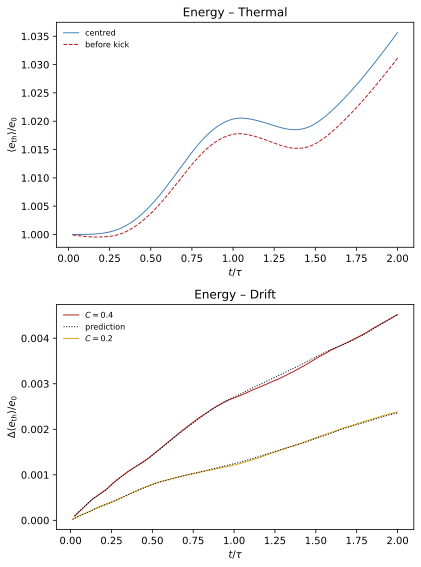

In [20]:
rng = np.random.default_rng(seed)
U = np.empty((4, 32, 32))
U[0] = rho0 * (1 + 0.5 * rng.random((32, 32)))
U[1:3] = 0.3 * U[0] * cs * rng.standard_normal((2, 32, 32))
U[3] = rho0 * cs**2 + 0.5 * np.sum(U[1:3]**2, axis=0) / U[0]
total = np.sum(U, axis=(1, 2))
for _ in range(100):
    U = energy_step(U, 2e-3, L / 32)
assert np.max(np.abs(np.sum(U, axis=(1, 2)) - total)) < 1e-10 * total[0]

weak = lambda: ForcingField(64, tau, 0.5, 2.0, seed)
e0 = rho0 * cs**2 / (gamma * (gamma - 1))
pairs = {C: (run_energy(64, weak(), 2 * tau, True, C), run_energy(64, weak(), 2 * tau, False, C)) for C in (0.4, 0.2)}
gaps = {C: np.interp(2 * tau, good["t"], good["thermal"]) - lagged["thermal"][-1] for C, (good, lagged) in pairs.items()}
for C, (good, lagged) in pairs.items():
    assert abs(gaps[C] / lagged["drift"][-1] - 1) < 0.1
assert 1.6 < gaps[0.4] / gaps[0.2] < 2.4

fig, ax = plt.subplots(2, 1, figsize=(6, 8))
good, lagged = pairs[0.4]
ax[0].plot(good["t"] / tau, good["thermal"] / e0, "-", color="steelblue", lw=1, label="centred")
ax[0].plot(lagged["t"] / tau, lagged["thermal"] / e0, "--", color="firebrick", lw=1, label="before kick")
ax[0].set(xlabel="$t/\\tau$", ylabel="$\\langle e_\\mathrm{th}\\rangle/e_0$", title="Energy – Thermal")
ax[0].legend(fontsize=8, edgecolor="none", handlelength=1.9, loc="upper left")

for C, col in [(0.4, "firebrick"), (0.2, "goldenrod")]:
    good, lagged = pairs[C]
    gap = np.interp(lagged["t"], good["t"], good["thermal"]) - lagged["thermal"]
    ax[1].plot(lagged["t"] / tau, gap / e0, "-", color=col, lw=1, label=f"$C = {C:g}$")
    ax[1].plot(lagged["t"] / tau, lagged["drift"] / e0, ":", color="k", lw=1, label="prediction" if C == 0.4 else None)
ax[1].set(xlabel="$t/\\tau$", ylabel="$\\Delta\\langle e_\\mathrm{th}\\rangle/e_0$", title="Energy – Drift")
ax[1].legend(fontsize=8, edgecolor="none", handlelength=1.9, loc="upper left")

fig.tight_layout()
plt.show()

### 7. Limits

The toy model is meant for quick comparisons between forcing methods and not for quantitative results, for several reasons:

* **Dimension:** turbulence in two dimensions has no vortex stretching and transfers kinetic energy towards large scales, so the spectra and the solenoidal runs in particular do not carry over to three dimensions
* **Resolution:** the dissipation is numerical and the range between driving and dissipation is short, so the injection rate at a given Mach number depends on the resolution
* **Statistics:** all averages cover few turnover times of a single realization, and for long correlation times the forcing barely changes during a run
* **Solver:** the flux with two waves smears shear layers and contacts, so vortices are more diffuse than with a full Riemann solver
* **Matching:** an amplitude calibrated at low resolution transfers to a higher resolution only roughly, so the measured Mach number should be reported next to the target